# G1 | Text: Phân loại phản hồi của sinh viên theo cảm xúc và chủ đề (UIT-VSFC)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/minhtho1503/data-analysis-visualization-g1/blob/main/projects/text/text.ipynb)

| | |
|---|---|
| Môn học | Nền tảng lập trình cho phân tích và trực quan dữ liệu (CO5177), học kỳ 261 (2026-2027) |
| Trường | Trường Đại học Bách Khoa - ĐHQG-HCM |
| Giảng viên | TS. Lê Thành Sách |
| Nhóm | G1 |
| Người phụ trách | Nguyễn Thị Thu An (2470315) |
| Dữ liệu | UIT-VSFC, Vietnamese Students' Feedback Corpus (16 175 câu tiếng Việt) |
| Bài toán | Phân loại văn bản có giám sát: cảm xúc (3 lớp, nhiệm vụ chính) và chủ đề (4 lớp, nhiệm vụ phụ) |

## Bối cảnh dữ liệu

Mỗi học kỳ, Trường Đại học Công nghệ Thông tin (UIT, ĐHQG-HCM) thu thập ý kiến phản hồi tự do của sinh viên để cải thiện chất lượng giảng dạy và dịch vụ của trường. Với hơn 16 000 câu phản hồi, việc đọc và phân loại thủ công tốn rất nhiều thời gian. Notebook này xây dựng mô hình tự động gán cho mỗi phản hồi hai nhãn:

* **Cảm xúc**: tiêu cực / trung tính / tích cực.
* **Chủ đề**: giảng viên / chương trình đào tạo / cơ sở vật chất / khác.

**Mục lục**

1. Thiết lập và tải dữ liệu
2. Mô tả dữ liệu
3. Kiểm tra chất lượng dữ liệu
4. Phân tích khám phá (EDA)
5. Tiền xử lý dữ liệu
6. Xây dựng mô hình
7. Đánh giá trên tập test
8. Dự đoán phản hồi mới
9. Kết luận

> **Cách chạy:** trên Google Colab, chọn *Runtime > Change runtime type > T4 GPU*, rồi *Runtime > Run all*.

## 1. Thiết lập và tải dữ liệu

In [1]:
# Cài đặt thư viện
import importlib.util

if importlib.util.find_spec("pyvi") is None:
    %pip install -q pyvi
if importlib.util.find_spec("sentence_transformers") is None:
    %pip install -q sentence-transformers

In [2]:
# Import thư viện
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import os, re, sys, time, random, unicodedata
import io
import urllib.request
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

from pyvi import ViTokenizer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

threadpool_limits(4)
print("Python", sys.version.split()[0])

Python 3.12.3


In [3]:
# Cấu hình
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

HF_DATASET = "uitnlp/vietnamese_students_feedback"

IN_COLAB = "google.colab" in sys.modules
HERE = Path("/content") if IN_COLAB else Path.cwd()
if (HERE / "projects" / "text").is_dir():
    HERE = HERE / "projects" / "text"
DATA_DIR = HERE / "data"
FIG_DIR = HERE / "figures"
RESULTS_DIR = HERE / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Du lieu: {DATA_DIR.relative_to(HERE)}/, hinh: {FIG_DIR.relative_to(HERE)}/, ket qua: {RESULTS_DIR.relative_to(HERE)}/")

Du lieu: data/, hinh: figures/, ket qua: results/


In [4]:
# Tải dữ liệu
SPLIT_FILES = {"train": "train", "val": "validation", "test": "test"}
SENT_ORDER = ["negative", "neutral", "positive"]
TOPIC_ORDER = ["lecturer", "program", "facility", "others"]

def download_data(dataset=HF_DATASET, out_dir=DATA_DIR):
    out_dir.mkdir(parents=True, exist_ok=True)
    for name in SPLIT_FILES.values():
        path = out_dir / f"{name}.json"
        if not path.exists():
            url = f"https://huggingface.co/api/datasets/{dataset}/parquet/default/{name}/0.parquet"
            with urllib.request.urlopen(url) as resp:
                pd.read_parquet(io.BytesIO(resp.read())).to_json(path, orient="records", force_ascii=False, indent=1)
        print(f"{path.relative_to(HERE)}: {path.stat().st_size / 1024:,.0f} KB")

download_data()

frames = []
for split, name in SPLIT_FILES.items():
    d = pd.read_json(DATA_DIR / f"{name}.json")
    raw_dtypes = d.dtypes.astype(str).to_dict()
    d["sentiment"] = d["sentiment"].map(dict(enumerate(SENT_ORDER)))
    d["topic"] = d["topic"].map(dict(enumerate(TOPIC_ORDER)))
    frames.append(d[["sentence", "sentiment", "topic"]].assign(split=split))
print("Cac cot goc:", raw_dtypes)

df = pd.concat(frames, ignore_index=True)
df["split"] = pd.Categorical(df["split"], ["train", "val", "test"])
print("df.shape =", df.shape)
df.head()

data/train.json: 1,457 KB
data/validation.json: 196 KB
data/test.json: 403 KB
Cac cot goc: {'sentence': 'str', 'sentiment': 'int64', 'topic': 'int64'}
df.shape = (16175, 4)


,sentence,sentiment,topic,split
0,slide giáo trình đầy đủ .,positive,program,train
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",positive,lecturer,train
2,đi học đầy đủ full điểm chuyên cần .,negative,program,train
3,chưa áp dụng công nghệ thông tin và các thiết ...,negative,lecturer,train
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",positive,lecturer,train


## 2. Mô tả dữ liệu

### 2.1 Tổng quan

- **Nguồn:** bộ dữ liệu **UIT-VSFC** (Vietnamese Students' Feedback Corpus), tải từ trang Hugging Face của nhóm tác giả (`uitnlp/vietnamese_students_feedback`, bản parquet), không cần đăng nhập.
- **Giấy phép:** dữ liệu được dùng cho mục đích nghiên cứu theo thỏa thuận của nhóm tác giả. Nhóm trích dẫn nguồn và không đưa dữ liệu lên repo.
- **Tác giả:** Kiet Van Nguyen, Vu Duc Nguyen, Phu X. V. Nguyen, Tham T. H. Truong và Ngan L.-T. Nguyen (nhóm UIT NLP), công bố trong bài báo "UIT-VSFC: Vietnamese Students' Feedback Corpus for Sentiment Analysis" tại hội nghị KSE 2018.
- **Nội dung:** các câu phản hồi do sinh viên viết trong khảo sát cuối học kỳ của Trường Đại học Công nghệ Thông tin, từ năm học 2014-2015 đến 2016-2017 (mỗi năm 175-227 giảng viên và 143-175 môn học). Mỗi câu được gán thủ công hai nhãn là cảm xúc và chủ đề. Văn bản đã được viết thường và tách dấu câu bằng khoảng trắng, tên giảng viên được ẩn danh thành `wzjwz<số>`, biểu tượng cảm xúc được viết thành từ như `colonsmile` (xem mục 3.3).
- **Độ tin cậy của nhãn:** bài báo báo cáo mức đồng thuận giữa những người gán nhãn (sau khi trừ phần trùng hợp ngẫu nhiên) là 91.2% với cảm xúc nhưng chỉ 71.07% với chủ đề, và chủ đề chương trình đào tạo chiếm 33% các trường hợp người gán nhãn không thống nhất. Nhãn chủ đề vì vậy kém chắc chắn hơn nhãn cảm xúc.
- **Cách chia:** nhóm giữ nguyên cách chia train / dev / test của tác giả và dùng làm train / validation / test, để kết quả so sánh được với bài báo gốc.

Bộ dữ liệu đáp ứng yêu cầu của đề với dữ liệu văn bản (mục 4.3 của đề): hơn 16 000 câu, nhiều hơn mức tối thiểu 2 000, và gần như toàn bộ là tiếng Việt.

In [5]:
n_samples = len(df)
n_vietnamese = df["sentence"].map(lambda s: any(ord(c) > 127 for c in s)).sum()
split_sizes = df["split"].value_counts().reindex(["train", "val", "test"])

print(f"Tong so cau: {n_samples:,}")
print(f"Cau co chu tieng Viet co dau: {n_vietnamese:,} ({n_vietnamese / n_samples:.1%})")
for split, n in split_sizes.items():
    print(f"{split:5s}: {n:6,d} cau ({n / n_samples:.1%})")

Tong so cau: 16,175
Cau co chu tieng Viet co dau: 16,152 (99.9%)
train: 11,426 cau (70.6%)
val  :  1,583 cau (9.8%)
test :  3,166 cau (19.6%)


**Bài toán và hướng tiếp cận**

Đây là bài toán phân tích cảm xúc (sentiment analysis), một dạng phân loại văn bản có giám sát: mô hình nhận vào một câu
phản hồi và dự đoán nhãn cảm xúc `negative`, `neutral` hoặc `positive`. Nhãn chủ đề được dự đoán theo cùng cách bằng
một mô hình riêng.

Mô hình phân loại chỉ làm việc với số, nên mỗi câu phải được biểu diễn thành một vector. Các bước chính:

1. Kiểm tra chất lượng và phân tích khám phá dữ liệu (mục 3, 4).
2. Tiền xử lý văn bản: làm sạch, đổi viết tắt, tách từ tiếng Việt (mục 5).
3. Biểu diễn câu thành vector số theo hai cách để so sánh: TF-IDF, trong đó mỗi chiều ứng với một từ hoặc cụm hai từ
   và giá trị là tần suất có trọng số (mục 5.5); và embedding câu lấy từ một mô hình embedding tiếng Việt huấn luyện
   sẵn (mục 6.3).
4. Huấn luyện các bộ phân lớp của scikit-learn trên tập train và chọn mô hình theo tập validation (mục 6).
5. Đánh giá một lần trên tập test (mục 7) và dự đoán phản hồi mới (mục 8).

### 2.2 Cấu trúc dữ liệu

Mỗi dòng là một câu phản hồi với 4 cột:

- `sentence`: nội dung câu phản hồi.
- `sentiment`: cảm xúc của câu, gồm `negative` (tiêu cực), `neutral` (trung tính) và `positive` (tích cực).
  Theo hướng dẫn gán nhãn của tác giả: `negative` gồm cả lời phàn nàn lẫn đề nghị, yêu cầu cải thiện; `neutral` là câu không nêu ý kiến hoặc chưa trọn ý, kể cả lời cảm ơn như *"em cảm ơn thầy"*; câu vừa khen vừa chê (thường có *nhưng*, *tuy nhiên*) được gán theo ý mạnh hơn.
- `topic`: chủ đề của câu, gồm `lecturer` (giảng viên), `program` (chương trình đào tạo, tên gốc là `training_program`), `facility` (cơ sở vật chất) và `others` (chủ đề khác hoặc không rõ chủ đề).
- `split`: câu thuộc tập nào trong cách chia gốc (`train`, `val`, `test`).

Trong file gốc, hai cột nhãn được lưu dưới dạng số (0, 1, 2, ...) và đã được đổi sang tên nhãn khi tải dữ liệu ở mục 1.

Năm dòng đầu của bảng dữ liệu:

In [6]:
df.head()

,sentence,sentiment,topic,split
0,slide giáo trình đầy đủ .,positive,program,train
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",positive,lecturer,train
2,đi học đầy đủ full điểm chuyên cần .,negative,program,train
3,chưa áp dụng công nghệ thông tin và các thiết ...,negative,lecturer,train
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",positive,lecturer,train


Hai câu ví dụ cho mỗi lớp cảm xúc trong tập train:

In [7]:
examples = pd.concat([g.sample(2, random_state=SEED) for _, g in df[df["split"] == "train"].groupby("sentiment")])
examples = examples[["sentence", "sentiment", "topic"]]
with pd.option_context("display.max_colwidth", 120):
    display(examples.reset_index(drop=True))

,sentence,sentiment,topic
0,"một số bài tập không rõ , không đi sâu .",negative,program
1,không sửa bài chi tiết vì nghĩ nó dễ so với học sinh .,negative,lecturer
2,em không có ý kiến về mục này .,neutral,others
3,có nghĩ 2 buổi không hề báo trước .,neutral,lecturer
4,cho học sinh tích cực thuyết trình bằng tiếng anh .,positive,lecturer
5,giảng viên truyền đạt dễ hiểu và nhiệt tình .,positive,lecturer


## 3. Kiểm tra chất lượng dữ liệu

### 3.1 Giá trị thiếu, trùng lặp và rò rỉ

Phần này kiểm tra ba lỗi thường gặp với dữ liệu văn bản:

- **Câu thiếu hoặc rỗng:** không dùng được để huấn luyện.
- **Sai dạng Unicode:** chữ có dấu như *ệ* có thể được lưu theo hai kiểu (NFC và NFD). Nhìn thì giống nhau nhưng máy coi là hai chuỗi khác nhau, nên cùng một từ có thể bị đếm thành hai từ.
- **Câu trùng:** câu lặp lại trong train làm mô hình học lệch, còn câu train xuất hiện lại trong validation hoặc test làm điểm đánh giá cao hơn thực tế.

In [8]:
empty = df["sentence"].isna() | df["sentence"].astype(str).str.strip().eq("")
nfc = df["sentence"].map(lambda s: unicodedata.normalize("NFC", str(s)))
tr = nfc[df["split"] == "train"].str.strip()
dup_within = tr.duplicated(keep="first")
conflicting = (df.loc[tr.index].assign(s=tr)[tr.duplicated(keep=False)]
               .groupby("s")["sentiment"].nunique().gt(1).sum())
leak = tr.isin(set(nfc[df["split"] != "train"].str.strip())) & ~dup_within

display(pd.DataFrame({"count": [
    int(df[["sentence", "sentiment", "topic"]].isna().any(axis=1).sum()),
    int(empty.sum()),
    int((nfc != df["sentence"]).sum()),
    int(dup_within.sum()),
    int(conflicting),
    int(leak.sum()),
    int(nfc[df["split"] == "val"].duplicated().sum()),
    int(nfc[df["split"] == "test"].duplicated().sum()),
]}, index=["missing_value", "empty_sentence", "not_nfc", "duplicate_in_train", "duplicate_with_conflicting_label",
           "train_in_val_or_test", "duplicate_in_val", "duplicate_in_test"]))
if dup_within.any():
    dup_text = tr[dup_within].iloc[0]
    display(df.loc[tr.index[tr == dup_text], ["sentence", "sentiment", "topic"]])

,count
missing_value,0
empty_sentence,0
not_nfc,0
duplicate_in_train,1
duplicate_with_conflicting_label,1
train_in_val_or_test,0
duplicate_in_val,0
duplicate_in_test,0


,sentence,sentiment,topic
11293,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...",positive,lecturer
11417,"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa th...",negative,lecturer


- **Nhận xét:**
  - Thiếu và rỗng: không có câu hay nhãn nào bị thiếu, không có câu rỗng.
  - Unicode: mọi câu đều đã ở dạng NFC.
  - Trùng lặp: train chỉ có 1 câu bị lặp, nhưng hai bản lại mang nhãn ngược nhau (`positive` và `negative`). Đây là câu vừa khen vừa chê (*"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa ..."*), loại câu khó sẽ gặp lại ở mục 7.5. Không có câu nào của train lặp lại trong validation hay test.
- **Quyết định:**
  - Bỏ bản lặp khỏi train (mục 5.1).
  - Vẫn giữ bước lọc câu rỗng và chuẩn hóa NFC, vì câu mới người dùng nhập ở mục 8 có thể rỗng hoặc ở dạng NFD.

### 3.2 Độ dài câu
Số từ được đếm sau khi bỏ các token chỉ gồm dấu câu. Câu dài bất thường được tìm bằng quy tắc IQR trên tập train,
sau đó đọc ví dụ ở hai đầu phân phối trước khi quyết định.

In [9]:
def n_words(s):
    return sum(1 for t in str(s).split() if re.search(r"\w", t))

df["n_words"] = df["sentence"].map(n_words)
df["n_chars"] = df["sentence"].astype(str).str.len()
display(df.groupby("split", observed=True)[["n_words", "n_chars"]].describe().round(1).T)

split            train     val    test
n_words count  11426.0  1583.0  3166.0
        mean      12.7    12.0    12.6
        std        9.5     9.4     9.7
        min        1.0     1.0     1.0
        25%        7.0     6.0     6.0
        50%       10.0     9.0    10.0
        75%       16.0    15.0    16.0
        max      147.0   150.0    93.0
n_chars count  11426.0  1583.0  3166.0
        mean      59.1    56.4    58.8
        std       43.1    42.8    44.1
        min        4.0     4.0     4.0
        25%       31.0    31.0    30.0
        50%       47.0    45.0    46.0
        75%       73.0    69.0    73.0
        max      660.0   718.0   411.0

In [10]:
trn = df[df["split"] == "train"]
q1, q3 = trn["n_words"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Quy tac IQR: cau dai bat thuong neu n_words > {upper:.0f} -> {(trn['n_words'] > upper).sum()} cau train "
      f"({(trn['n_words'] > upper).mean():.1%})")
print(f"Cau rat ngan (<= 2 tu): {(trn['n_words'] <= 2).sum()} cau train")
print("\nNgan nhat:")
display(trn.nsmallest(6, "n_words")[["sentence", "sentiment", "topic", "n_words"]])
print("Dai nhat:")
display(trn.nlargest(3, "n_words")[["sentence", "sentiment", "topic", "n_words"]]
        .assign(sentence=lambda d: d["sentence"].str.slice(0, 160) + " ..."))

Quy tac IQR: cau dai bat thuong neu n_words > 30 -> 663 cau train (5.8%)
Cau rat ngan (<= 2 tu): 141 cau train

Ngan nhat:


,sentence,sentiment,topic,n_words
205,không !,neutral,others,1
366,chán .,negative,lecturer,1
378,điểm .,neutral,others,1
756,nope .,neutral,others,1
823,thân .,neutral,others,1
2730,không .,neutral,others,1


Dai nhat:


,sentence,sentiment,topic,n_words
3754,thầy cho nghỉ quá nhiểu mà không sắp xếp giáo ...,negative,lecturer,147
8670,"thầy nên hướng dẫn cụ thể về vấn đề đồ án , bọ...",negative,lecturer,112
7057,"nội dung học chất lượng nhưng khá đơn giản , t...",negative,program,102


- **Nhận xét:**
  - Độ dài chung: câu phản hồi khá ngắn, trung vị 10 từ (khoảng 47 ký tự) ở train và 75% số câu không quá 16 từ. Ba tập có độ dài gần như nhau (trung bình 12.0-12.7 từ).
  - Câu dài: theo quy tắc IQR, 663 câu train (5.8%) dài hơn 30 từ. Đọc ví dụ thì đây là các góp ý gồm nhiều ý, không phải lỗi nhập liệu.
  - Câu ngắn: 141 câu chỉ có 1-2 từ (*"chán ."*, *"không ."*), phần lớn là kiểu "không có ý kiến" thuộc lớp `neutral`.
- **Quyết định:** giữ tất cả. Bỏ đi chỉ làm mất thông tin, và độ dài không ảnh hưởng nhiều đến mô hình vì mọi vector TF-IDF đều được chuẩn hóa L2 (mục 5.5).

### 3.3 Token đặc biệt và viết tắt

Bộ dữ liệu có ba loại token thay thế: tên giảng viên đã ẩn danh (`wzjwz208`), biểu tượng cảm xúc được viết thành từ
(`colonsmile`, `colonsad`, ...) và dấu câu viết thành từ (`doubledot` = ":", `dotdotdot` = "...").

Sinh viên cũng hay gõ tắt, ví dụ *ko* (không), *đc* (được), *gv* (giảng viên). Từ điển viết tắt của nhóm được khai báo
ngay trong notebook dưới dạng danh sách cặp (`abbreviation`, `full_form`), tức từ viết tắt và dạng đầy đủ. Số lần xuất hiện được đếm sau
khi bỏ dấu câu và chữ số, giống cách `clean_text()` xử lý ở mục 5.2.

In [11]:
NAME_RE = re.compile(r"wzjwz\d+")
EMO_RE = re.compile(r"colon[a-z]+")
PUNCT_WORD_RE = re.compile(r"\b(?:doubledot|dotdotdot)\b")

emo_counts = Counter(t for s in trn["sentence"] for t in EMO_RE.findall(s))
print(f"Cau co ten an danh: {trn['sentence'].str.contains(NAME_RE).sum()} "
      f"(so ma ten khac nhau: {len(set(t for s in trn['sentence'] for t in NAME_RE.findall(s)))})")
print(f"Cau co token bieu tuong cam xuc: {trn['sentence'].str.contains(EMO_RE).sum()}")
print(f"Cau co doubledot / dotdotdot: {trn['sentence'].str.contains(PUNCT_WORD_RE).sum()}")
display(pd.DataFrame(
    [(e, c, trn.loc[trn["sentence"].str.contains(rf"\b{e}\b"), "sentiment"].value_counts().idxmax())
     for e, c in emo_counts.most_common(6)],
    columns=["token", "count", "majority_sentiment"]))

Cau co ten an danh: 211 (so ma ten khac nhau: 233)
Cau co token bieu tuong cam xuc: 85
Cau co doubledot / dotdotdot: 88


,token,count,majority_sentiment
0,colonsmile,27,positive
1,colonsmilesmile,12,positive
2,colonsad,11,negative
3,coloncontemn,9,positive
4,colonlove,7,positive
5,colonbigsmile,5,negative


In [12]:
TEENCODE_PAIRS = [
    ("av", "anh văn"), ("đươc", "được"), ("silde", "slide"), ("đc", "được"), ("nhìu", "nhiều"), ("ko", "không"),
    ("lun", "luôn"), ("pđt", "phòng đào tạo"), ("trc", "trước"), ("csvc", "cơ sở vật chất"),
    ("ctdt", "chương trình đào tạo"), ("ctđt", "chương trình đào tạo"), ("cx", "cũng"), ("dc", "được"),
    ("dzậy", "vậy"), ("gv", "giảng viên"), ("hc", "học"), ("hok", "không"), ("kh", "không"), ("khg", "không"),
    ("khum", "không"), ("mik", "mình"), ("mk", "mình"), ("mn", "mọi người"), ("ng", "người"),
    ("ntn", "như thế nào"), ("oke", "ok"), ("okie", "ok"), ("r", "rồi"), ("sv", "sinh viên"), ("thik", "thích"),
    ("tkb", "thời khóa biểu"), ("vs", "với"), ("wá", "quá"), ("zậy", "vậy"),
]
teencode = pd.DataFrame(TEENCODE_PAIRS, columns=["abbreviation", "full_form"])
TEENCODE = dict(TEENCODE_PAIRS)

def raw_tokens(s):
    return re.sub(r"[\d_]+", " ", re.sub(r"[^\w\s]", " ", s)).split()

all_tokens = Counter(t for s in df["sentence"] for t in raw_tokens(s))
train_tokens = Counter(t for s in trn["sentence"] for t in raw_tokens(s))
teencode["count_train"] = teencode["abbreviation"].map(lambda a: train_tokens.get(a, 0))
teencode["count_all"] = teencode["abbreviation"].map(lambda a: all_tokens.get(a, 0))
n_sent = df["sentence"].map(lambda s: any(t in TEENCODE for t in raw_tokens(s))).sum()
display(teencode.sort_values(["count_all", "abbreviation"], ascending=[False, True]).reset_index(drop=True))
print(f"Token viet tat: {teencode['count_all'].sum()} / {sum(all_tokens.values()):,} token, "
      f"trong {n_sent} / {len(df):,} cau")

,abbreviation,full_form,count_train,count_all
0,av,anh văn,3,6
1,đươc,được,4,6
2,silde,slide,3,4
3,đc,được,0,3
4,nhìu,nhiều,1,2
5,ko,không,1,1
6,lun,luôn,0,1
7,pđt,phòng đào tạo,1,1
8,trc,trước,1,1
9,csvc,cơ sở vật chất,0,0


Token viet tat: 25 / 203,147 token, trong 21 / 16,175 cau


- **Nhận xét:**
  - Tên ẩn danh: 211 câu train có tên ẩn danh với 233 mã khác nhau. Mỗi mã chỉ xuất hiện vài lần nên bản thân mã không có ý nghĩa, nhưng việc câu có nhắc tên giảng viên thì có thể có ích.
  - Biểu tượng cảm xúc: hiếm (85 câu, chưa tới 1%) nhưng mang cảm xúc, `colonsmile` thường đi với câu `positive`, `colonsad` với câu `negative`. Bài báo lưu ý một số biểu tượng như `:v` xuất hiện ở cả câu khen lẫn câu chê, nên đây chỉ là tín hiệu phụ.
  - Viết tắt: từ điển viết tắt được xây dựng bằng cách tách toàn bộ dữ liệu thành từ, dùng LLM rà soát để tìm từ viết tắt và cách viết sai, rồi kiểm tra thủ công từng từ trong câu gốc. Các từ dễ hiểu sai bị loại, ví dụ `k` (phần còn lại của `k6`, `320k` sau khi bỏ chữ số) và `bt` (có thể là "bài tập" hoặc "bình thường"). Từ điển có thêm một số cách viết tắt phổ biến khi gõ như `gv`, `sv`, `khum` dù chúng không có trong dữ liệu. Kết quả cho thấy dữ liệu gần như không có viết tắt: chỉ 25 token trong 21 câu, nhiều nhất là `av` (anh văn) và `đươc`, đúng như bài báo mô tả: tác giả đã thay từ viết tắt bằng từ đầy đủ và sửa lỗi chính tả trước khi công bố.
- **Quyết định:**
  - Thay mọi `wzjwz<số>` bằng một token chung `personname`.
  - Giữ token biểu tượng cảm xúc, bỏ `doubledot` / `dotdotdot` như các dấu câu khác.
  - Dùng từ điển viết tắt này để đổi viết tắt sang dạng đầy đủ, cho cả dữ liệu và câu mới ở mục 8.
  - Tất cả được làm trong `clean_text()` (mục 5.2).

### 3.4 Tổng kết: vấn đề và cách xử lý

| Vấn đề | Kết quả kiểm tra | Cách xử lý | Mục |
|---|---|---|---|
| Giá trị thiếu, câu rỗng | 0 | nếu có thì bỏ khỏi train/val/test | 5.1 |
| Unicode không ở dạng NFC | 0 câu | vẫn chuẩn hóa NFC, cần cho câu mới | 5.1, 5.2 |
| Câu trùng trong train | 1 câu, hai nhãn trái ngược | bỏ bản lặp khỏi train | 5.1 |
| Câu train có trong val/test | 0 câu | nếu có thì bỏ khỏi train, không sửa val/test | 5.1 |
| Câu rất ngắn / rất dài | 141 câu <= 2 từ, 663 câu > 30 từ | giữ lại; chuẩn hóa L2 trong TF-IDF | 5.5 |
| Tên ẩn danh `wzjwz<số>` | 211 câu, 233 mã | thay bằng `personname` | 5.2 |
| Biểu tượng cảm xúc `colon...` | 85 câu | giữ lại vì mang cảm xúc | 5.2 |
| Dấu câu viết thành từ | 88 câu | bỏ cùng các dấu câu khác | 5.2 |
| Viết tắt / teencode | 25 token trong 21 câu | đổi sang dạng đầy đủ theo từ điển viết tắt, cần cho câu mới | 5.2 |
| Nhãn mất cân bằng | `neutral` 4.0% (mục 4.1) | chọn mô hình theo macro-F1, dùng `class_weight="balanced"` | 6.1 |

## 4. Phân tích khám phá (EDA)
Phân tích khám phá chỉ dùng **tập train** (riêng Hình 1 so sánh ba tập), để mọi hiểu biết về dữ liệu không đến
từ tập test.

In [13]:
# Hàm vẽ biểu đồ
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
SENT_COLORS = {"negative": "#c0392b", "neutral": "#95a5a6", "positive": "#27ae60"}
SPLIT_COLORS = {"train": "#0072B2", "val": "#E69F00", "test": "#4D4D4D"}

FIG_NO = 0
def show_fig(fig, name, caption):
    global FIG_NO
    FIG_NO += 1
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Hình {FIG_NO}.** {caption}"))

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

### 4.1 Các nhãn có cân bằng không?
Nếu nhãn mất cân bằng, độ chính xác (accuracy) sẽ che mất một lớp nhỏ bị nhận sai, và có thể cần trọng số lớp.

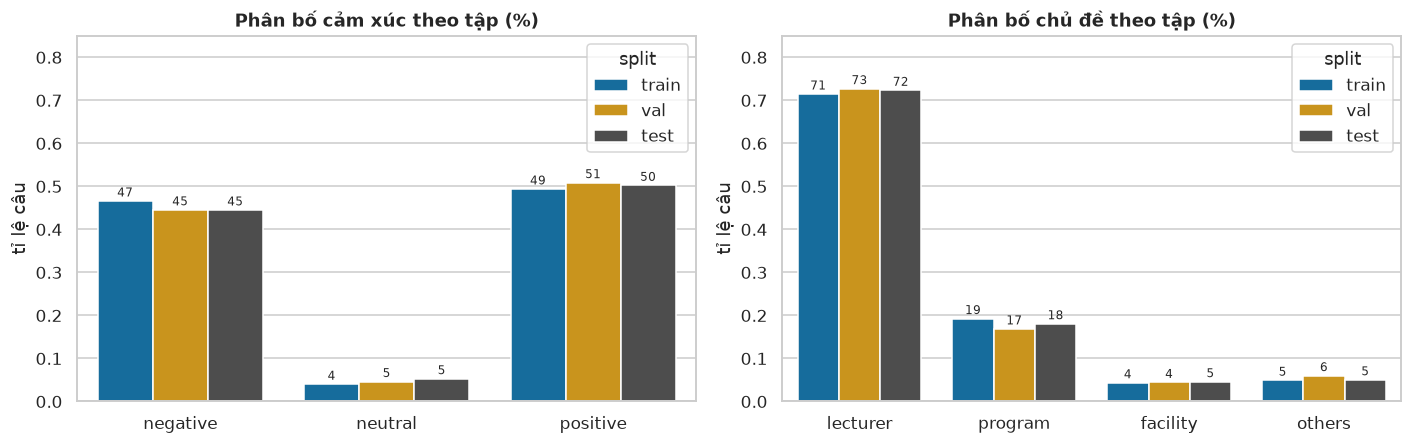

**Hình 1.** Cả hai nhãn đều mất cân bằng. Trong train, tích cực chiếm 49.4%, tiêu cực 46.6% và **trung tính chỉ 4.0%**; chủ đề *lecturer* chiếm 71.5% trong khi *facility* chỉ 4.3%. Tỉ lệ giữa ba tập chênh nhau tối đa 2.1 điểm, nên cách chia chính thức là đại diện. Kết luận: dùng **macro-F1** (mọi lớp có trọng số như nhau) bên cạnh accuracy.

In [14]:
train_raw = df[df["split"] == "train"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, order, name in [(axes[0], "sentiment", SENT_ORDER, "cảm xúc"), (axes[1], "topic", TOPIC_ORDER, "chủ đề")]:
    share = (df.groupby("split", observed=True)[col].value_counts(normalize=True)
               .rename("share").reset_index())
    sns.barplot(data=share, x=col, y="share", hue="split", order=order, ax=ax, palette=SPLIT_COLORS)
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{v.get_height()*100:.0f}" for v in c], fontsize=8, padding=1)
    ax.set_ylabel("tỉ lệ câu"); ax.set_xlabel(""); ax.set_ylim(0, 0.85)
    ax.set_title(f"Phân bố {name} theo tập (%)")
fig.tight_layout()

tr_s = train_raw["sentiment"].value_counts(normalize=True)
tr_t = train_raw["topic"].value_counts(normalize=True)
by_split = df.groupby("split", observed=True)["sentiment"].value_counts(normalize=True).unstack()
max_diff = (by_split.max() - by_split.min()).max()
show_fig(fig, "fig01_label_distribution",
    f"Cả hai nhãn đều mất cân bằng. Trong train, tích cực chiếm {pct(tr_s['positive'])}, tiêu cực {pct(tr_s['negative'])} "
    f"và **trung tính chỉ {pct(tr_s['neutral'])}**; chủ đề *lecturer* chiếm {pct(tr_t['lecturer'])} trong khi *facility* "
    f"chỉ {pct(tr_t['facility'])}. Tỉ lệ giữa ba tập chênh nhau tối đa {100*max_diff:.1f} điểm, nên cách chia chính thức "
    f"là đại diện. Kết luận: dùng **macro-F1** (mọi lớp có trọng số như nhau) bên cạnh accuracy.")

### 4.2 Mỗi chủ đề nhận bao nhiêu phản hồi tiêu cực?
Mỗi chủ đề được xem theo hai con số: số câu tiêu cực (có bao nhiêu lời phàn nàn) và tỉ lệ câu tiêu cực trong chủ đề đó
(phản hồi về chủ đề này chủ yếu là phàn nàn hay không).

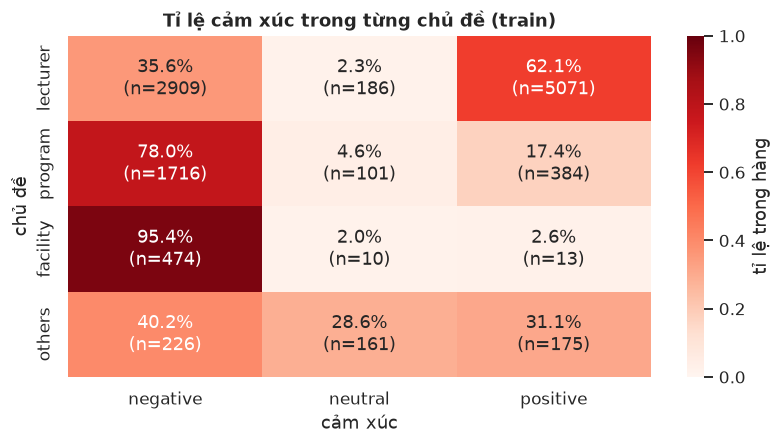

**Hình 2.** Tỉ lệ và số câu tiêu cực theo chủ đề: facility 95.4% (474 câu); program 78.0% (1,716 câu); others 40.2% (226 câu); lecturer 35.6% (2,909 câu). Kết luận: *facility* có ít câu nhưng gần như toàn là phàn nàn, còn *lecturer* có tỉ lệ tiêu cực chỉ 35.6% nhưng chiếm 54.6% tổng số câu tiêu cực (2,909 / 5,325).

In [15]:
ct = pd.crosstab(train_raw["topic"], train_raw["sentiment"]).loc[TOPIC_ORDER, SENT_ORDER]
ct_pct = ct.div(ct.sum(axis=1), axis=0)
annot = ct_pct.map(lambda v: f"{100*v:.1f}%") + "\n(n=" + ct.astype(str) + ")"

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(ct_pct, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "tỉ lệ trong hàng"}, ax=ax)
ax.set_title("Tỉ lệ cảm xúc trong từng chủ đề (train)"); ax.set_xlabel("cảm xúc"); ax.set_ylabel("chủ đề")
fig.tight_layout()

neg_share = ct_pct["negative"].sort_values(ascending=False)
most_abs = ct["negative"].idxmax()
per_topic = "; ".join(f"{t} {pct(ct_pct.loc[t, 'negative'])} ({ct.loc[t, 'negative']:,} câu)" for t in neg_share.index)
show_fig(fig, "fig02_topic_sentiment_heatmap",
    f"Tỉ lệ và số câu tiêu cực theo chủ đề: {per_topic}. Kết luận: *{neg_share.index[0]}* có ít câu nhưng gần như "
    f"toàn là phàn nàn, còn *{most_abs}* có tỉ lệ tiêu cực chỉ {pct(ct_pct.loc[most_abs, 'negative'])} nhưng chiếm "
    f"{pct(ct.loc[most_abs, 'negative'] / ct['negative'].sum())} tổng số câu tiêu cực "
    f"({ct.loc[most_abs, 'negative']:,} / {ct['negative'].sum():,}).")

Tỉ lệ của từng cặp chủ đề và cảm xúc trên toàn bộ tập train, đặt cạnh bảng III của bài báo (tính trên toàn bộ dữ liệu):

In [16]:
PAPER_SHARE = pd.DataFrame(
    [[25.38, 1.81, 33.57, 71.76], [14.39, 1.00, 3.40, 18.79], [4.21, 0.08, 0.11, 4.40], [2.01, 1.43, 1.61, 5.04],
     [45.99, 4.32, 49.69, 100.0]],
    index=TOPIC_ORDER + ["total"], columns=SENT_ORDER + ["total"])
share = (pd.crosstab(train_raw["topic"], train_raw["sentiment"], normalize="all", margins=True, margins_name="total") * 100)
share = share.loc[TOPIC_ORDER + ["total"], SENT_ORDER + ["total"]].round(2)
display(pd.concat({"train": share, "paper": PAPER_SHARE}, axis=1))

train                             paper                         
sentiment negative neutral positive   total negative neutral positive   total
lecturer     25.46    1.63    44.38   71.47    25.38    1.81    33.57   71.76
program      15.02    0.88     3.36   19.26    14.39    1.00     3.40   18.79
facility      4.15    0.09     0.11    4.35     4.21    0.08     0.11    4.40
others        1.98    1.41     1.53    4.92     2.01    1.43     1.61    5.04
total        46.60    4.01    49.39  100.00    45.99    4.32    49.69  100.00

- **Nhận xét:**
  - Tỉ lệ trên tập train gần như trùng với bảng III của bài báo (chênh nhau dưới 1 điểm phần trăm ở mọi ô còn lại), nên dữ liệu tải về khớp với bộ dữ liệu đã công bố.
  - Riêng ô `lecturer` x `positive` lệch lớn (44.38% so với 33.57%). Đây có vẻ là lỗi đánh máy trong bài báo: hàng `lecturer` của bài báo cộng lại chỉ được 60.76% thay vì 71.76%, còn nếu ô này là 44.57% thì cả hàng lẫn cột `positive` (49.69%) đều khớp.

### 4.3 Độ dài câu có khác nhau giữa các lớp cảm xúc không?
Nếu một lớp luôn dài hơn, mô hình có thể học độ dài thay vì nội dung.

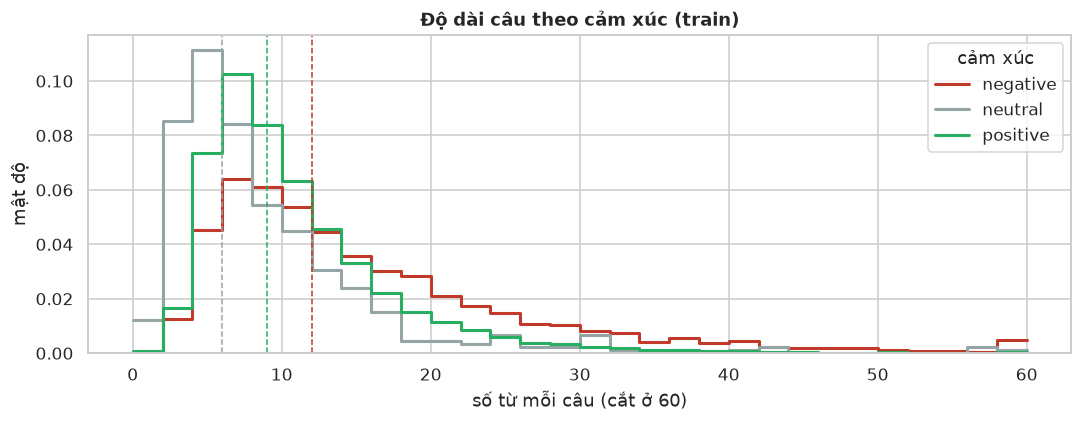

**Hình 3.** Trung vị độ dài là 12 từ với câu tiêu cực, 6 với trung tính và 9 với tích cực (nét đứt); chỉ 2.0% số câu dài hơn 40 từ (dài nhất 147 từ). Kết luận: câu tiêu cực dài nhất (sinh viên giải thích điều chưa tốt), câu trung tính ngắn nhất (thường là 'không có ý kiến'), nhưng các phân phối chồng lên nhau nhiều, nên độ dài một mình không tách được các lớp.

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
for lab in SENT_ORDER:
    sns.histplot(train_raw.loc[train_raw["sentiment"] == lab, "n_words"].clip(upper=60), bins=30, binrange=(0, 60),
                 stat="density", element="step", fill=False, lw=2, color=SENT_COLORS[lab], label=lab, ax=ax)
med = train_raw.groupby("sentiment")["n_words"].median()
for lab in SENT_ORDER:
    ax.axvline(med[lab], color=SENT_COLORS[lab], ls="--", lw=1)
ax.set_xlabel("số từ mỗi câu (cắt ở 60)"); ax.set_ylabel("mật độ")
ax.set_title("Độ dài câu theo cảm xúc (train)"); ax.legend(title="cảm xúc")
fig.tight_layout()
show_fig(fig, "fig03_sentence_length",
    f"Trung vị độ dài là {med['negative']:.0f} từ với câu tiêu cực, {med['neutral']:.0f} với trung tính và "
    f"{med['positive']:.0f} với tích cực (nét đứt); chỉ {pct((train_raw['n_words'] > 40).mean())} số câu dài hơn 40 từ "
    f"(dài nhất {train_raw['n_words'].max()} từ). Kết luận: "
    + ("câu tiêu cực dài nhất (sinh viên giải thích điều chưa tốt), câu trung tính ngắn nhất (thường là 'không có ý "
       "kiến'), " if med['negative'] > med['positive'] > med['neutral'] else "")
    + "nhưng các phân phối chồng lên nhau nhiều, nên độ dài một mình không tách được các lớp.")

Bài báo chia độ dài câu thành các khoảng 5 từ (bảng IV và V). Cùng cách chia trên tập train, theo cảm xúc và theo chủ đề (% trên toàn tập train):

In [18]:
bins = [0, 5, 10, 15, 20, 25, 30, np.inf]
bin_names = ["1-5", "6-10", "11-15", "16-20", "21-25", "26-30", ">30"]
length_bin = pd.cut(train_raw["n_words"], bins=bins, labels=bin_names)
by_sentiment = pd.crosstab(length_bin, train_raw["sentiment"], normalize="all", margins=True, margins_name="total") * 100
by_topic = pd.crosstab(length_bin, train_raw["topic"], normalize="all", margins=True, margins_name="total") * 100
display(by_sentiment[SENT_ORDER + ["total"]].round(2))
display(by_topic[TOPIC_ORDER + ["total"]].round(2))
short = (train_raw["n_words"] <= 15).mean()
print(f"Cau co <= 15 tu: {short:.1%} tap train (bai bao: hon 83%)")

sentiment,negative,neutral,positive,total
n_words,,,,
1-5,5.43,1.67,8.98,16.08
6-10,14.07,1.33,21.98,37.38
11-15,10.06,0.58,10.49,21.13
16-20,6.56,0.17,4.25,10.98
21-25,3.85,0.11,1.98,5.93
26-30,2.39,0.05,0.82,3.26
>30,4.24,0.11,0.88,5.23
total,46.60,4.01,49.39,100.00


topic,lecturer,program,facility,others,total
n_words,,,,,
1-5,11.26,2.27,0.42,2.13,16.08
6-10,28.64,5.79,1.40,1.56,37.38
11-15,15.33,4.19,1.05,0.55,21.13
16-20,7.44,2.69,0.60,0.26,10.98
21-25,3.93,1.60,0.24,0.17,5.93
26-30,1.99,0.91,0.26,0.11,3.26
>30,2.88,1.82,0.39,0.15,5.23
total,71.47,19.26,4.35,4.92,100.00


Cau co <= 15 tu: 74.6% tap train (bai bao: hon 83%)


- **Nhận xét:**
  - Xu hướng giống bài báo: câu `negative` dài hơn câu `positive`. Ở nhóm trên 30 từ, câu `negative` chiếm 4.24% tập train còn `positive` chỉ 0.88%; ở nhóm 1-5 từ thì ngược lại (5.43% so với 8.98%). Câu chê thường kèm lý do và đề xuất nên dài hơn.
  - Chủ đề `others` tập trung ở câu rất ngắn: khoảng 43% câu `others` (2.13 trên 4.92 điểm phần trăm) chỉ có 1-5 từ, phù hợp với định nghĩa `others` là câu không rõ chủ đề.
  - Tỉ lệ câu không quá 15 từ là 74.6%, thấp hơn mức "hơn 83%" của bài báo. Có thể bài báo đếm từ sau khi tách từ (một từ nhiều âm tiết tính là 1), còn notebook đếm âm tiết, nên câu trong notebook trông dài hơn.

### 4.4 Từ nào đặc trưng cho mỗi lớp cảm xúc?
Đếm unigram và bigram theo âm tiết trong từng lớp sau khi bỏ một danh sách ngắn hư từ tiếng Việt (*và, là,
của, có, các, ...*) và các token thay thế. Dùng biểu đồ cột thay vì word cloud để so sánh được độ dài. Cột **có
màu** là n-gram chỉ nằm trong top 15 của lớp đó; cột xám là n-gram dùng chung với lớp khác.

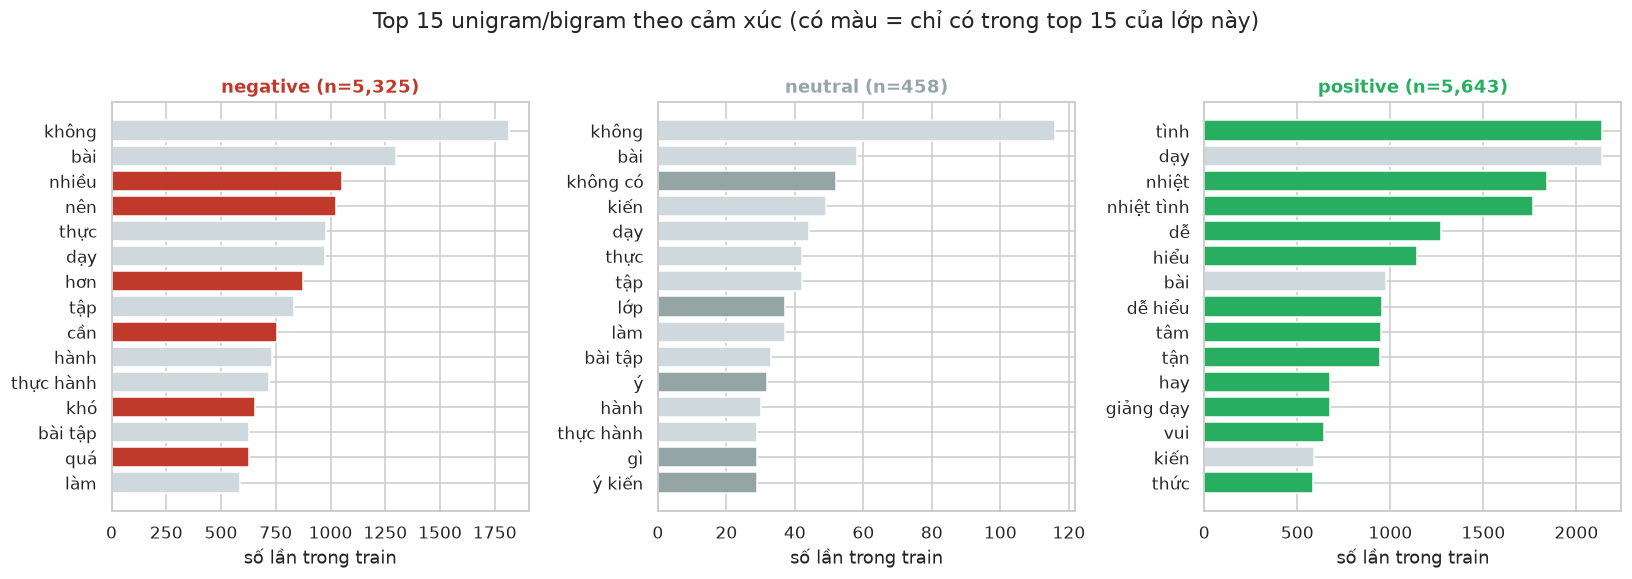

**Hình 4.** Câu tích cực chủ yếu là từ khen ('tình', 'nhiệt', 'nhiệt tình', 'dễ'); câu tiêu cực là từ góp ý hoặc phàn nàn ('nhiều', 'nên', 'hơn', 'cần'); câu trung tính là kiểu 'không có ý kiến' ('không có', 'lớp', 'ý', 'gì'). Kết luận: túi n-gram đã mang tín hiệu cảm xúc mạnh, đó là lý do dùng mô hình TF-IDF. Âm tiết 'nhiệt' và 'tình' được đếm riêng *và* trong bigram 'nhiệt tình' (một từ): từ tiếng Việt gồm nhiều âm tiết, đó là lý do tách từ ở mục 5.3.

In [19]:
STOP = set('''và là của có các những được cho thì với này một em cũng để trong khi ra đã về như mà đến từ vào sẽ
đó nào ạ nữa vì do mình chúng ta ở lên việc rất thầy cô môn học sinh viên giảng'''.split())

def ngrams_of(sentence):
    toks = [t for t in sentence.split() if re.fullmatch(r"\w+", t) and not re.match(r"(wzjwz|colon)", t)
            and not t.isdigit()]
    grams = [t for t in toks if t not in STOP]
    grams += [f"{a} {b}" for a, b in zip(toks, toks[1:]) if a not in STOP or b not in STOP]
    return grams

top_ng = {lab: Counter(g for s in train_raw.loc[train_raw["sentiment"] == lab, "sentence"] for g in ngrams_of(s))
               .most_common(15) for lab in SENT_ORDER}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
for ax, lab in zip(axes, SENT_ORDER):
    others = {g for o in SENT_ORDER if o != lab for g, _ in top_ng[o]}
    grams, counts = zip(*top_ng[lab])
    colors = [SENT_COLORS[lab] if g not in others else "#cfd8dc" for g in grams]
    ax.barh(list(grams)[::-1], list(counts)[::-1], color=colors[::-1])
    ax.set_title(f"{lab} (n={int((train_raw['sentiment'] == lab).sum()):,})", color=SENT_COLORS[lab])
    ax.set_xlabel("số lần trong train")
fig.suptitle("Top 15 unigram/bigram theo cảm xúc (có màu = chỉ có trong top 15 của lớp này)", y=1.01)
fig.tight_layout()

uniq = {lab: [g for g, _ in top_ng[lab] if g not in {x for o in SENT_ORDER if o != lab for x, _ in top_ng[o]}]
        for lab in SENT_ORDER}
show_fig(fig, "fig04_top_ngrams",
    f"Câu tích cực chủ yếu là từ khen ({', '.join(repr(g) for g in uniq['positive'][:4])}); câu tiêu cực là từ góp ý "
    f"hoặc phàn nàn ({', '.join(repr(g) for g in uniq['negative'][:4])}); câu trung tính là kiểu 'không có ý kiến' "
    f"({', '.join(repr(g) for g in uniq['neutral'][:4])}). Kết luận: túi n-gram đã mang tín hiệu cảm xúc mạnh, đó là lý "
    f"do dùng mô hình TF-IDF. Âm tiết 'nhiệt' và 'tình' được đếm riêng *và* trong bigram 'nhiệt tình' (một từ): từ "
    f"tiếng Việt gồm nhiều âm tiết, đó là lý do tách từ ở mục 5.3.")

### 4.5 Tổng kết EDA

- **Nhãn mất cân bằng:** lớp `neutral` chỉ chiếm 4.0% tập train, chủ đề `lecturer` chiếm 71.5%. Vì vậy mô hình được
  chọn theo macro-F1 thay vì accuracy, và Logistic Regression, LinearSVC luôn
  dùng `class_weight="balanced"` (mục 6.1).
- **Phản hồi tiêu cực theo chủ đề:** `facility` có tỉ lệ tiêu cực cao nhất (95.4%, 474 câu), còn `lecturer` có tỉ lệ
  thấp nhất (35.6%) nhưng nhiều câu tiêu cực nhất (2 909 câu, 54.6% tổng số câu tiêu cực). Phản hồi về cơ sở vật chất
  ít nhưng gần như toàn là phàn nàn, còn phản hồi về giảng viên có nhiều lời phàn nàn nhất.
- **Độ dài câu:** phần lớn câu ngắn (trung vị 6 từ với `neutral`, 9 với `positive`, 12 với `negative`). Các lớp có độ
  dài khác nhau nhưng chồng lấn nhiều, nên độ dài không được dùng làm đặc trưng.
- **Từ vựng:** từ khen (*nhiệt tình*, *dễ*) và từ góp ý, phàn nàn (*nên*, *cần*, *hơn*) tách biệt rõ giữa các lớp,
  nên biểu diễn câu bằng tần suất từ (TF-IDF) là hướng hợp lý.

## 5. Tiền xử lý dữ liệu
Các bước được áp dụng theo thứ tự sau:

| Mục | Bước | Áp dụng cho |
|---|---|---|
| 5.1 | Bỏ câu rỗng, chuẩn hóa NFC; bỏ câu trùng và câu rò rỉ khỏi train | câu rỗng, NFC: train/val/test; câu trùng, câu rò rỉ: train |
| 5.2 | Hàm làm sạch `clean_text()` | train/val/test (và câu mới ở mục 8) |
| 5.3 | Tách từ bằng `pyvi` | train/val/test |
| 5.4 | Mã hóa nhãn | train/val/test (fit trên train) |
| 5.5 | TF-IDF (tương đương *scaling* với văn bản) | train/val/test (fit trên train, bên trong `Pipeline`) |
| 5.6 | Kích thước cuối cùng của ba tập | |

**Nguyên tắc chống rò rỉ dữ liệu:** các quy tắc theo từng dòng (chuẩn hóa, làm sạch) được áp dụng như nhau cho
mọi tập; mọi thống kê học từ dữ liệu (từ vựng TF-IDF, IDF, bộ mã hóa nhãn) chỉ fit trên train. Validation và
test không bị bỏ dòng nào (trừ câu rỗng), để giữ nguyên cách chia chính thức.

### 5.1 Bỏ câu rỗng, chuẩn hóa NFC; bỏ câu trùng và câu rò rỉ khỏi train

In [20]:
n_before = len(df)
df = df[~empty].copy()
df["sentence"] = df["sentence"].map(lambda s: unicodedata.normalize("NFC", s).strip())

tr = df[df["split"] == "train"]
dup_within = tr["sentence"].duplicated(keep="first")
leak = tr["sentence"].isin(set(df.loc[df["split"] != "train", "sentence"])) & ~dup_within
df = df.drop(index=tr.index[dup_within | leak]).reset_index(drop=True)

print(f"Tong so cau: {n_before:,} -> {len(df):,}")
print("So cau theo tap:", df["split"].value_counts().reindex(["train", "val", "test"]).to_dict())

Tong so cau: 16,175 -> 16,174
So cau theo tap: {'train': 11425, 'val': 1583, 'test': 3166}


### 5.2 Hàm làm sạch văn bản
`clean_text()` thực hiện: chuẩn hóa NFC, viết thường (không đổi gì trên bộ dữ liệu này nhưng cần cho câu mới ở
mục 8), thay mọi tên ẩn danh bằng một token chung `personname`, bỏ dấu câu và chữ số, đổi viết tắt sang dạng đầy đủ
và gộp khoảng trắng. Token biểu tượng cảm xúc được giữ lại vì chúng mang cảm xúc (mục 3.3).

In [21]:
def clean_text(s):
    s = unicodedata.normalize("NFC", str(s)).lower()
    s = NAME_RE.sub(" personname ", s)
    s = PUNCT_WORD_RE.sub(" ", s)
    s = re.sub(r"[^\w\s]", " ", s)  # \w is Unicode-aware, so Vietnamese letters are kept
    s = re.sub(r"[\d_]+", " ", s)
    return " ".join(TEENCODE.get(t, t) for t in s.split())

df["text_clean"] = df["sentence"].map(clean_text)
demo_idx = df.index[df["sentence"].str.contains(r"wzjwz|colon|\d|,", regex=True)][:5]
with pd.option_context("display.max_colwidth", 100):
    display(df.loc[demo_idx, ["sentence", "text_clean"]])

empty_after = df["text_clean"].eq("")
print("Cau rong sau khi lam sach, theo tap:", df.loc[empty_after, "split"].value_counts().to_dict())
n_tr = (df["split"] == "train").sum()
df = df[~(empty_after & (df["split"] == "train"))].reset_index(drop=True)
print(f"Train: {n_tr:,} -> {(df['split'] == 'train').sum():,} sau khi bo cau rong sau lam sach")

,sentence,text_clean
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",nhiệt tình giảng dạy gần gũi với sinh viên
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ngay trên lớp .",thầy giảng bài hay có nhiều bài tập ví dụ ngay trên lớp
5,"giảng viên đảm bảo thời gian lên lớp , tích cực trả lời câu hỏi của sinh viên , thường xuyên đặt...",giảng viên đảm bảo thời gian lên lớp tích cực trả lời câu hỏi của sinh viên thường xuyên đặt câu...
6,"em sẽ nợ môn này , nhưng em sẽ học lại ở các học kỳ kế tiếp .",em sẽ nợ môn này nhưng em sẽ học lại ở các học kỳ kế tiếp
7,"thời lượng học quá dài , không đảm bảo tiếp thu hiệu quả .",thời lượng học quá dài không đảm bảo tiếp thu hiệu quả


Cau rong sau khi lam sach, theo tap: {'train': 0, 'val': 0, 'test': 0}
Train: 11,425 -> 11,425 sau khi bo cau rong sau lam sach


### 5.3 Tách từ tiếng Việt bằng `pyvi`
Trong tiếng Việt, khoảng trắng tách **âm tiết**, không tách từ: *giảng viên* là một từ gồm hai âm tiết.
`pyvi.ViTokenizer` nối các âm tiết của một từ bằng dấu `_`, nên TF-IDF thấy `giảng_viên` là một đặc trưng. Nhóm giữ **cả hai** cột:
`text_seg` (từ) cho TF-IDF và `text_clean` (âm tiết) cho mô hình embedding ở mục 6.3, vì mô hình này tự tách câu thành token.

In [22]:
t0 = time.perf_counter()
df["text_seg"] = df["text_clean"].map(ViTokenizer.tokenize)
print(f"Tach tu {len(df):,} cau trong {time.perf_counter() - t0:.1f} s")
print("Vi du:", ViTokenizer.tokenize("giảng viên dạy hay"))
display(df.loc[df["text_clean"].str.contains("giảng viên|nhiệt tình|cơ sở vật chất"), ["text_clean", "text_seg"]]
          .head(5))
print(f"So tu nhieu am tiet tim duoc: {df['text_seg'].str.count('_').sum():,} "
      f"(trung binh {df['text_seg'].str.count('_').mean():.2f} moi cau)")

Tach tu 16,174 cau trong 1.1 s
Vi du: giảng_viên dạy hay


,text_clean,text_seg
1,nhiệt tình giảng dạy gần gũi với sinh viên,nhiệt_tình giảng_dạy gần_gũi với sinh_viên
5,giảng viên đảm bảo thời gian lên lớp tích cực ...,giảng_viên đảm_bảo thời_gian lên_lớp tích_cực ...
16,nhiệt tình vui vẻ,nhiệt_tình vui_vẻ
17,thấy nhiệt tình trong việc trao đổi giúp đỡ về...,thấy nhiệt_tình trong việc trao_đổi giúp_đỡ về...
22,thầy nhiệt tình quan tâm tới sinh viên,thầy nhiệt_tình quan_tâm tới sinh_viên


So tu nhieu am tiet tim duoc: 49,749 (trung binh 3.08 moi cau)


### 5.4 Mã hóa nhãn
`LabelEncoder` đổi nhãn chữ sang số nguyên theo thứ tự bảng chữ cái. Bộ mã hóa được fit trên nhãn của train và
dùng lại cho validation, test; `inverse_transform` đổi dự đoán về lại tên nhãn.

In [23]:
le_sent = LabelEncoder().fit(df.loc[df["split"] == "train", "sentiment"])
le_topic = LabelEncoder().fit(df.loc[df["split"] == "train", "topic"])
df["y_sent"] = le_sent.transform(df["sentiment"])
df["y_topic"] = le_topic.transform(df["topic"])
display(pd.concat([
    pd.DataFrame({"task": "sentiment", "label": le_sent.classes_, "code": range(len(le_sent.classes_))}),
    pd.DataFrame({"task": "topic", "label": le_topic.classes_, "code": range(len(le_topic.classes_))}),
], ignore_index=True))

,task,label,code
0,sentiment,negative,0
1,sentiment,neutral,1
2,sentiment,positive,2
3,topic,facility,0
4,topic,lecturer,1
5,topic,others,2
6,topic,program,3


### 5.5 Từ văn bản thành số: TF-IDF
Với dữ liệu số, ta chuẩn hóa để không đặc trưng nào lấn át vì đơn vị đo. Với văn bản, bước tương đương là
**TF-IDF + chuẩn hóa L2**: số lần xuất hiện được làm dịu (`sublinear_tf`: 1 + log tf), từ xuất hiện ở mọi câu
nhận trọng số IDF thấp, và mỗi vector câu được đưa về độ dài 1, nên câu dài và câu ngắn ở cùng thang đo.

Cấu hình chung của mọi mô hình TF-IDF: unigram và bigram theo từ, `min_df=2` (bỏ n-gram chỉ gặp một lần) và một
`token_pattern` giữ lại từ một ký tự (mặc định scikit-learn bỏ qua các từ tiếng Việt như *ở*, *à*). Bộ vector hóa
chỉ **fit trên train**, bên trong `Pipeline`.

In [24]:
def make_vec():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

vec_demo = make_vec().fit(train_df["text_seg"])
X_demo = vec_demo.transform(train_df["text_seg"])
norms = np.sqrt(X_demo.multiply(X_demo).sum(axis=1)).A1
print(f"Tu vung (unigram + bigram theo tu, min_df=2): {len(vec_demo.vocabulary_):,} dac trung")
print(f"Ma tran train: {X_demo.shape}, trung binh {X_demo.getnnz(axis=1).mean():.1f} gia tri khac 0 moi dong "
      f"(do thua {100 * (1 - X_demo.nnz / np.prod(X_demo.shape)):.2f}%)")
print(f"Chuan L2 cua cac dong: min={norms[norms > 0].min():.3f}, max={norms.max():.3f}")
idf = pd.Series(vec_demo.idf_, index=vec_demo.get_feature_names_out())
print("IDF thap nhat (pho bien nhat):", ", ".join(idf.nsmallest(5).index))

Tu vung (unigram + bigram theo tu, min_df=2): 13,025 dac trung
Ma tran train: (11425, 13025), trung binh 15.3 gia tri khac 0 moi dong (do thua 99.88%)
Chuan L2 cua cac dong: min=1.000, max=1.000
IDF thap nhat (pho bien nhat): thầy, sinh_viên, dạy, và, nhiệt_tình


### 5.6 Kích thước cuối cùng của ba tập
`n_sentences` là số câu, `share` là tỉ lệ so với toàn bộ dữ liệu, `neutral_share` là tỉ lệ câu `neutral` trong tập đó.

In [25]:
sizes = pd.DataFrame({"n_sentences": [len(train_df), len(val_df), len(test_df)]}, index=["train", "val", "test"])
sizes["share"] = (sizes["n_sentences"] / sizes["n_sentences"].sum()).map(pct)
sizes["neutral_share"] = [pct((d["sentiment"] == "neutral").mean()) for d in (train_df, val_df, test_df)]
display(sizes)

,n_sentences,share,neutral_share
train,11425,70.6%,4.0%
val,1583,9.8%,4.6%
test,3166,19.6%,5.3%


## 6. Xây dựng mô hình

Mục này gồm hai bước, làm như nhau cho cả hai nhãn `sentiment` và `topic`:

1. Giữ cố định đặc trưng TF-IDF và so sánh ba bộ phân lớp để tìm bộ phân lớp tốt nhất (mục 6.2).
2. Giữ bộ phân lớp tốt nhất đó, thay TF-IDF bằng embedding tiếng Việt để xem một cách biểu diễn câu tốt hơn có giúp
   không (mục 6.3).

### 6.1 Thước đo và cách chọn mô hình

- **Thước đo:** macro-F1 trên tập validation. Lớp `neutral` chỉ chiếm khoảng 4%, nên một mô hình không bao giờ đoán
  `neutral` vẫn có accuracy cao. Macro-F1 lấy trung bình F1 của các lớp với trọng số như nhau nên phạt lỗi đó.
  Accuracy và weighted-F1 (thước đo của bài báo gốc) vẫn được báo cáo.
- **Cách chọn:** mỗi mô hình được huấn luyện trên train và chấm trên validation, mô hình có macro-F1 validation cao
  nhất được chọn. Tập test chỉ được dùng một lần, ở mục 7.
- **Bộ phân lớp** (đều của scikit-learn, dùng tham số mặc định):

| Bộ phân lớp | Ghi chú |
|---|---|
| `MultinomialNB` (Naive Bayes) | baseline |
| `LogisticRegression` | `class_weight="balanced"`; bài báo gốc cũng dùng Logistic Regression làm baseline |
| `LinearSVC` (SVM tuyến tính) | `class_weight="balanced"` |

Vì lớp `neutral` chỉ chiếm 4% (mục 4.1), Logistic Regression và LinearSVC luôn dùng `class_weight="balanced"`: lỗi ở
lớp nhỏ bị phạt nặng hơn, để mô hình không bỏ qua lớp `neutral`.

In [26]:
SPLIT_DF = {"train": train_df, "val": val_df, "test": test_df}
TASK_COL = {"sentiment": "y_sent", "topic": "y_topic"}
FEAT_COL = {"tfidf_seg": "text_seg"}
EMB = {}

def make_clf(family):
    if family == "NaiveBayes":
        return MultinomialNB()
    if family == "LogReg":
        return LogisticRegression(class_weight="balanced", max_iter=3000, random_state=SEED)
    if family == "LinearSVC":
        return LinearSVC(class_weight="balanced", random_state=SEED)
    raise ValueError(family)

def get_X(features, split):
    return EMB[split] if features == "emb" else SPLIT_DF[split][FEAT_COL[features]].values

def scores(y_true, y_pred):
    return {"acc": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "weighted_f1": f1_score(y_true, y_pred, average="weighted")}

def run(family, features, task, eval_split="val"):
    model = make_clf(family)
    if features != "emb":
        model = make_pipeline(make_vec(), model)
    t0 = time.perf_counter()
    model.fit(get_X(features, "train"), SPLIT_DF["train"][TASK_COL[task]])
    pred = model.predict(get_X(features, eval_split))
    secs = time.perf_counter() - t0
    return model, pred, {**scores(SPLIT_DF[eval_split][TASK_COL[task]], pred), "fit_predict_s": secs}

### 6.2 So sánh các bộ phân lớp trên TF-IDF
Ba bộ phân lớp dùng chung đặc trưng TF-IDF (unigram và bigram trên `text_seg`, mục 5.5).

In [27]:
TASKS = ["sentiment", "topic"]
FAMILIES = ["NaiveBayes", "LogReg", "LinearSVC"]

rows = []
for task in TASKS:
    for fam in FAMILIES:
        rows.append({"task": task, "family": fam, "features": "tfidf_seg", **run(fam, "tfidf_seg", task)[2]})
val_tfidf = pd.DataFrame(rows)
display(val_tfidf.drop(columns="fit_predict_s").round(4))

BEST_FAMILY = {task: val_tfidf[val_tfidf["task"] == task].sort_values("macro_f1").iloc[-1]["family"] for task in TASKS}
print("Bo phan lop tot nhat:", BEST_FAMILY)

,task,family,features,acc,macro_f1,weighted_f1
0,sentiment,NaiveBayes,tfidf_seg,0.8863,0.6046,0.8658
1,sentiment,LogReg,tfidf_seg,0.8869,0.7525,0.8944
2,sentiment,LinearSVC,tfidf_seg,0.9103,0.7729,0.9094
3,topic,NaiveBayes,tfidf_seg,0.8048,0.4803,0.7610
4,topic,LogReg,tfidf_seg,0.8193,0.7271,0.8323
5,topic,LinearSVC,tfidf_seg,0.8617,0.7484,0.8612


Bo phan lop tot nhat: {'sentiment': 'LinearSVC', 'topic': 'LinearSVC'}


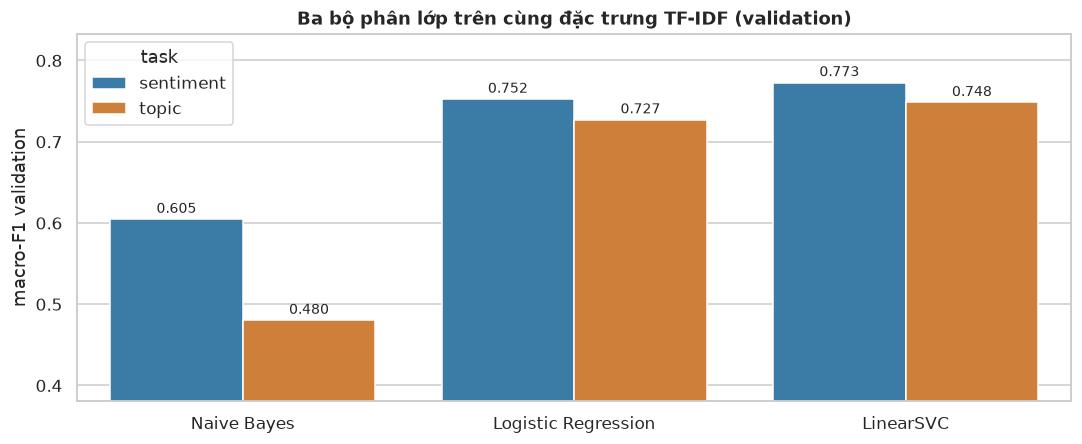

**Hình 5.** Macro-F1 validation (sentiment: LinearSVC 0.773, Logistic Regression 0.752, Naive Bayes 0.605; topic: LinearSVC 0.748, Logistic Regression 0.727, Naive Bayes 0.480). Kết luận: bộ phân lớp tốt nhất là LinearSVC với `sentiment`, LinearSVC với `topic`.

In [28]:
FAMILY_LABEL = {"NaiveBayes": "Naive Bayes", "LogReg": "Logistic Regression", "LinearSVC": "LinearSVC"}
fig, ax = plt.subplots(figsize=(10, 4.2))
d = val_tfidf.assign(model=val_tfidf["family"].map(FAMILY_LABEL))
sns.barplot(data=d, x="model", y="macro_f1", hue="task", ax=ax, palette=["#2980b9", "#e67e22"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2, fontsize=9)
ax.set_ylim(max(0, d["macro_f1"].min() - 0.1), min(1, d["macro_f1"].max() + 0.06))
ax.set_xlabel(""); ax.set_ylabel("macro-F1 validation")
ax.set_title("Ba bộ phân lớp trên cùng đặc trưng TF-IDF (validation)")
fig.tight_layout()

per_task = "; ".join(
    f"{task}: " + ", ".join(f"{FAMILY_LABEL[r['family']]} {r['macro_f1']:.3f}"
                            for _, r in val_tfidf[val_tfidf["task"] == task].sort_values("macro_f1", ascending=False).iterrows())
    for task in TASKS)
show_fig(fig, "fig05_model_comparison",
    f"Macro-F1 validation ({per_task}). Kết luận: bộ phân lớp tốt nhất là "
    + ", ".join(f"{FAMILY_LABEL[BEST_FAMILY[t]]} với `{t}`" for t in TASKS) + ".")

- **Nhận xét:** LinearSVC đạt macro-F1 validation cao nhất ở cả hai nhãn (0.7729 với `sentiment`, 0.7484 với `topic`), Logistic Regression kém khoảng 2 điểm (0.7525 và 0.7271). Naive Bayes thấp hơn hẳn (0.6046 và 0.4803) dù accuracy vẫn cao (0.8863 với `sentiment`): mô hình làm tốt ở lớp lớn nhưng kém ở các lớp nhỏ như `neutral` và `others`, và Naive Bayes cũng không dùng trọng số lớp. Đây là ví dụ cho thấy vì sao mô hình được chọn theo macro-F1 thay vì accuracy.
- **Quyết định:** dùng LinearSVC cho bước tiếp theo ở cả hai nhãn.

### 6.3 Embedding tiếng Việt có giúp bộ phân lớp tốt nhất không?
Giữ bộ phân lớp tốt nhất ở mục 6.2, chỉ thay đặc trưng TF-IDF bằng embedding câu của
`AITeamVN/Vietnamese_Embedding`. Đây là mô hình embedding câu cho tiếng Việt, được fine-tune từ BGE-M3 (khoảng 568
triệu tham số, vector 1024 chiều, giấy phép Apache 2.0). Mô hình được dùng như một **hàm trích đặc trưng có sẵn**,
không fine-tune thêm.

Mô hình này nhận **`text_clean` (chưa tách từ)**, không phải `text_seg`: nó tự tách câu thành token và được huấn luyện
trên văn bản tiếng Việt thường, không có dấu `_` nối các âm tiết.

In [29]:
import torch
import transformers
from sentence_transformers import SentenceTransformer
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()

EMBED_MODEL = "AITeamVN/Vietnamese_Embedding"
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE_NAME = "GPU" if DEVICE == "cuda" else "CPU"
encoder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
encoder.max_seq_length = 128

for split, d in SPLIT_DF.items():
    EMB[split] = encoder.encode(d["text_clean"].tolist(), batch_size=256, normalize_embeddings=True,
                                show_progress_bar=False, convert_to_numpy=True)
print(f"Thiet bi: {DEVICE_NAME}; kich thuoc embedding (train): {EMB['train'].shape}")

Thiet bi: GPU; kich thuoc embedding (train): (11425, 1024)


In [30]:
rows = [{"task": task, "family": BEST_FAMILY[task], "features": "emb", **run(BEST_FAMILY[task], "emb", task)[2]}
        for task in TASKS]
val_all = pd.concat([val_tfidf, pd.DataFrame(rows)], ignore_index=True)

compare = val_all[val_all.apply(lambda r: r["family"] == BEST_FAMILY[r["task"]], axis=1)]
display(compare.drop(columns="fit_predict_s").round(4).reset_index(drop=True))

,task,family,features,acc,macro_f1,weighted_f1
0,sentiment,LinearSVC,tfidf_seg,0.9103,0.7729,0.9094
1,topic,LinearSVC,tfidf_seg,0.8617,0.7484,0.8612
2,sentiment,LinearSVC,emb,0.9299,0.8244,0.9311
3,topic,LinearSVC,emb,0.8585,0.7496,0.8633


- **Nhận xét:** với `sentiment`, embedding tiếng Việt cho macro-F1 validation cao hơn TF-IDF rõ rệt: 0.8244 so với 0.7729 (+5.2 điểm). Với `topic`, hai cách gần như bằng nhau (0.7496 so với 0.7484). Có thể vì cảm xúc phụ thuộc vào nghĩa của cả câu, trong khi chủ đề thường lộ ra qua vài từ khóa (*giảng viên*, *phòng*, *máy chiếu*) mà TF-IDF đã bắt được.
- **Quyết định:** theo cách chọn ở mục 6.1, embedding tiếng Việt + LinearSVC là mô hình cuối cùng cho cả hai nhãn (mục 6.4), dù với `topic` mức chênh rất nhỏ. Các mô hình TF-IDF vẫn được đánh giá trên test để so sánh.

### 6.4 Mô hình cuối cùng
Với mỗi nhãn, tập test được dùng một lần cho cả 4 mô hình ở trên (ba bộ phân lớp trên TF-IDF và bộ phân lớp tốt nhất
trên embedding), để mục 7 so sánh chúng trên cùng một tập test. **Mô hình cuối cùng** của mỗi nhãn là mô hình có
macro-F1 validation cao nhất; không chỉnh lại gì sau khi thấy điểm test.

In [31]:
TEST_CONFIGS = [dict(task=r["task"], family=r["family"], features=r["features"], val_macro_f1=r["macro_f1"],
                     role="embedding" if r["features"] == "emb" else r["family"]) for _, r in val_all.iterrows()]
FINAL = {task: max([c for c in TEST_CONFIGS if c["task"] == task], key=lambda c: c["val_macro_f1"]) for task in TASKS}
for c in TEST_CONFIGS:
    c["final"] = c is FINAL[c["task"]]
display(pd.DataFrame(TEST_CONFIGS).round(4))
print("Mo hinh cuoi cung:", {t: f"{c['family']} [{c['features']}]" for t, c in FINAL.items()})

,task,family,features,val_macro_f1,role,final
0,sentiment,NaiveBayes,tfidf_seg,0.6046,NaiveBayes,False
1,sentiment,LogReg,tfidf_seg,0.7525,LogReg,False
2,sentiment,LinearSVC,tfidf_seg,0.7729,LinearSVC,False
3,topic,NaiveBayes,tfidf_seg,0.4803,NaiveBayes,False
4,topic,LogReg,tfidf_seg,0.7271,LogReg,False
5,topic,LinearSVC,tfidf_seg,0.7484,LinearSVC,False
6,sentiment,LinearSVC,emb,0.8244,embedding,True
7,topic,LinearSVC,emb,0.7496,embedding,True


Mo hinh cuoi cung: {'sentiment': 'LinearSVC [emb]', 'topic': 'LinearSVC [emb]'}


## 7. Đánh giá trên tập test

### 7.1 Kết quả trên test và so sánh với bài báo gốc
Mỗi cấu hình đã khai báo được huấn luyện lại trên train và đánh giá **một lần** trên tập test. Bài báo gốc báo
cáo weighted-F1 khoảng 0.88 (cảm xúc) và 0.84 (chủ đề) với mô hình Logistic Regression.

In [32]:
TEST_PRED, TEST_MODEL, rows = {}, {}, []
for i, c in enumerate(TEST_CONFIGS):
    model, pred, s = run(c["family"], c["features"], c["task"], eval_split="test")
    TEST_PRED[i], TEST_MODEL[i] = pred, model
    rows.append({"task": c["task"], "role": c["role"], "model": c["family"], "features": c["features"], "final": c["final"],
                 "val_macro_f1": c["val_macro_f1"], "test_acc": s["acc"], "test_macro_f1": s["macro_f1"],
                 "test_weighted_f1": s["weighted_f1"], "fit_predict_s": s["fit_predict_s"]})
test_res = pd.DataFrame(rows)

def cfg_index(task, role):
    return next(i for i, c in enumerate(TEST_CONFIGS) if c["task"] == task and c["role"] == role)

i_sent = cfg_index("sentiment", FINAL["sentiment"]["role"])
i_topic = cfg_index("topic", FINAL["topic"]["role"])
display(test_res.drop(columns=["fit_predict_s"]).round(4))

,task,role,model,features,final,val_macro_f1,test_acc,test_macro_f1,test_weighted_f1
0,sentiment,NaiveBayes,NaiveBayes,tfidf_seg,False,0.6046,0.8699,0.5955,0.8466
1,sentiment,LogReg,LogReg,tfidf_seg,False,0.7525,0.8692,0.7201,0.8748
2,sentiment,LinearSVC,LinearSVC,tfidf_seg,False,0.7729,0.8961,0.7388,0.8917
3,topic,NaiveBayes,NaiveBayes,tfidf_seg,False,0.4803,0.8184,0.5440,0.7809
4,topic,LogReg,LogReg,tfidf_seg,False,0.7271,0.8143,0.7283,0.8282
5,topic,LinearSVC,LinearSVC,tfidf_seg,False,0.7484,0.8547,0.7516,0.8562
6,sentiment,embedding,LinearSVC,emb,True,0.8244,0.9169,0.8011,0.9172
7,topic,embedding,LinearSVC,emb,True,0.7496,0.8500,0.7522,0.8574


**Nhận xét.** Mô hình cuối cùng cho cả hai nhãn là **embedding tiếng Việt + LinearSVC**. Trên test, mô hình `sentiment` đạt accuracy 0.9169, macro-F1 0.8011, weighted-F1 0.9172; mô hình `topic` đạt 0.8500, 0.7522 và 0.8574. Weighted-F1 của cả hai cao hơn bài báo gốc (khoảng 0.88 và 0.84). Thứ tự các mô hình trên test giống trên validation ở cả hai nhãn: Naive Bayes thấp nhất, rồi Logistic Regression, LinearSVC trên TF-IDF, và cao nhất là LinearSVC trên embedding. Với `topic`, embedding và TF-IDF gần như bằng nhau (macro-F1 0.7522 so với 0.7516), và accuracy của embedding còn thấp hơn một chút (0.8500 so với 0.8547).

### 7.2 Mỗi lớp được nhận ra tốt đến đâu?
Báo cáo theo lớp cho precision, recall và F1 của từng lớp; macro-F1 là trung bình không trọng số của các F1 này.

In [33]:
for task, i, le, col in [("sentiment", i_sent, le_sent, "y_sent"), ("topic", i_topic, le_topic, "y_topic")]:
    print(f"=== {task}: {TEST_CONFIGS[i]['family']} [{TEST_CONFIGS[i]['features']}] ===")
    print(classification_report(test_df[col], TEST_PRED[i], target_names=le.classes_, digits=3))

=== sentiment: LinearSVC [emb] ===
              precision    recall  f1-score   support

    negative      0.932     0.950     0.941      1409
     neutral      0.517     0.533     0.525       167
    positive      0.947     0.928     0.937      1590

    accuracy                          0.917      3166
   macro avg      0.799     0.804     0.801      3166
weighted avg      0.918     0.917     0.917      3166

=== topic: LinearSVC [emb] ===
              precision    recall  f1-score   support

    facility      0.882     0.931     0.906       145
    lecturer      0.950     0.882     0.915      2290
      others      0.396     0.560     0.464       159
     program      0.675     0.781     0.724       572

    accuracy                          0.850      3166
   macro avg      0.726     0.789     0.752      3166
weighted avg      0.870     0.850     0.857      3166



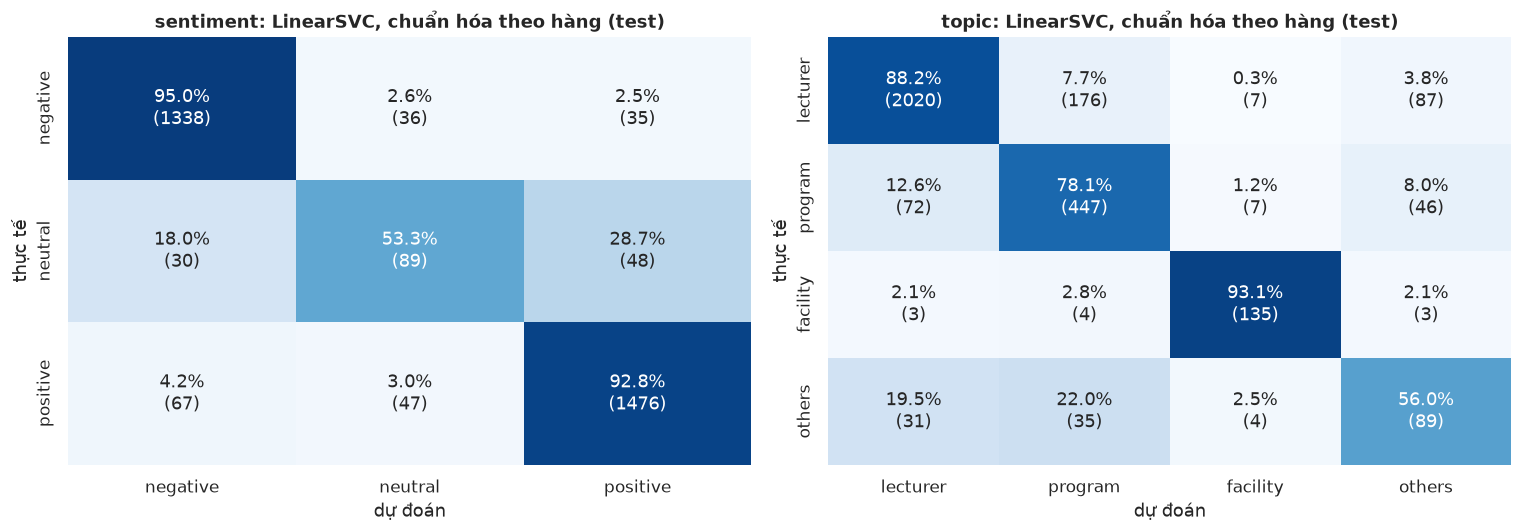

**Hình 6.** Cảm xúc: recall 95.0% với tiêu cực và 92.8% với tích cực, nhưng **chỉ 53.3% với trung tính**; 18.0% câu trung tính bị đoán là tiêu cực và 28.7% là tích cực. Chủ đề: recall lecturer 88.2%, facility 93.1%, còn *others* chỉ 56.0% (một lớp "còn lại" không có từ vựng riêng). Kết luận: điểm yếu là hai lớp nhỏ và mơ hồ, *trung tính* và *others*.

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_info = {}
for ax, task, i, le, col, order in [(axes[0], "sentiment", i_sent, le_sent, "y_sent", SENT_ORDER),
                                    (axes[1], "topic", i_topic, le_topic, "y_topic", TOPIC_ORDER)]:
    labels = le.transform(order)
    cm = confusion_matrix(test_df[col], TEST_PRED[i], labels=labels, normalize="true")
    cmn = confusion_matrix(test_df[col], TEST_PRED[i], labels=labels)
    annot = np.array([[f"{100*cm[r, c]:.1f}%\n({cmn[r, c]})" for c in range(len(order))] for r in range(len(order))])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, xticklabels=order, yticklabels=order,
                ax=ax, cbar=False)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("thực tế")
    ax.set_title(f"{task}: {TEST_CONFIGS[i]['family']}, chuẩn hóa theo hàng (test)")
    cm_info[task] = pd.DataFrame(cm, index=order, columns=order)
fig.tight_layout()

cs, ctp = cm_info["sentiment"], cm_info["topic"]
show_fig(fig, "fig06_confusion_matrices",
    f"Cảm xúc: recall {pct(cs.loc['negative','negative'])} với tiêu cực và {pct(cs.loc['positive','positive'])} với tích "
    f"cực, nhưng **chỉ {pct(cs.loc['neutral','neutral'])} với trung tính**; {pct(cs.loc['neutral','negative'])} câu trung "
    f"tính bị đoán là tiêu cực và {pct(cs.loc['neutral','positive'])} là tích cực. Chủ đề: recall lecturer "
    f"{pct(ctp.loc['lecturer','lecturer'])}, facility {pct(ctp.loc['facility','facility'])}, còn *others* chỉ "
    f"{pct(ctp.loc['others','others'])} (một lớp \"còn lại\" không có từ vựng riêng). Kết luận: điểm yếu là hai lớp nhỏ "
    f"và mơ hồ, *trung tính* và *others*.")

F1 từng lớp so với mô hình Logistic Regression của bài báo (bảng IX và X, cùng tập test):

In [35]:
PAPER_F1 = {"sentiment": {"negative": 0.9052, "neutral": 0.3399, "positive": 0.9132},
            "topic": {"facility": 0.8873, "lecturer": 0.9112, "others": 0.3810, "program": 0.6719}}
rows = []
for task, i, le, col in [("sentiment", i_sent, le_sent, "y_sent"), ("topic", i_topic, le_topic, "y_topic")]:
    f1 = f1_score(test_df[col], TEST_PRED[i], average=None, labels=range(len(le.classes_)))
    for label, value in zip(le.classes_, f1):
        rows.append({"task": task, "label": label, "f1_ours": round(value, 4), "f1_paper": PAPER_F1[task][label]})
per_class = pd.DataFrame(rows)
per_class["diff"] = (per_class["f1_ours"] - per_class["f1_paper"]).round(4)
display(per_class)

,task,label,f1_ours,f1_paper,diff
0,sentiment,negative,0.9409,0.9052,0.0357
1,sentiment,neutral,0.5251,0.3399,0.1852
2,sentiment,positive,0.9374,0.9132,0.0242
3,topic,facility,0.9060,0.8873,0.0187
4,topic,lecturer,0.9149,0.9112,0.0037
5,topic,others,0.4635,0.3810,0.0825
6,topic,program,0.7245,0.6719,0.0526


- **Nhận xét:** mô hình cuối cùng có F1 cao hơn mô hình Logistic Regression của bài báo ở cả 7 lớp. Mức tăng lớn nhất nằm ở các lớp nhỏ và khó: `neutral` (+0.185), `others` (+0.083) và `program` (+0.053); các lớp còn lại chỉ tăng 0.004-0.036. Tuy vậy `neutral` (0.53) và `others` (0.46) vẫn là hai lớp yếu nhất, giống bài báo.

### 7.3 TF-IDF hay embedding tiếng Việt?
So sánh bộ phân lớp tốt nhất trên TF-IDF và trên embedding tiếng Việt (mục 6.3) trên cùng tập test.

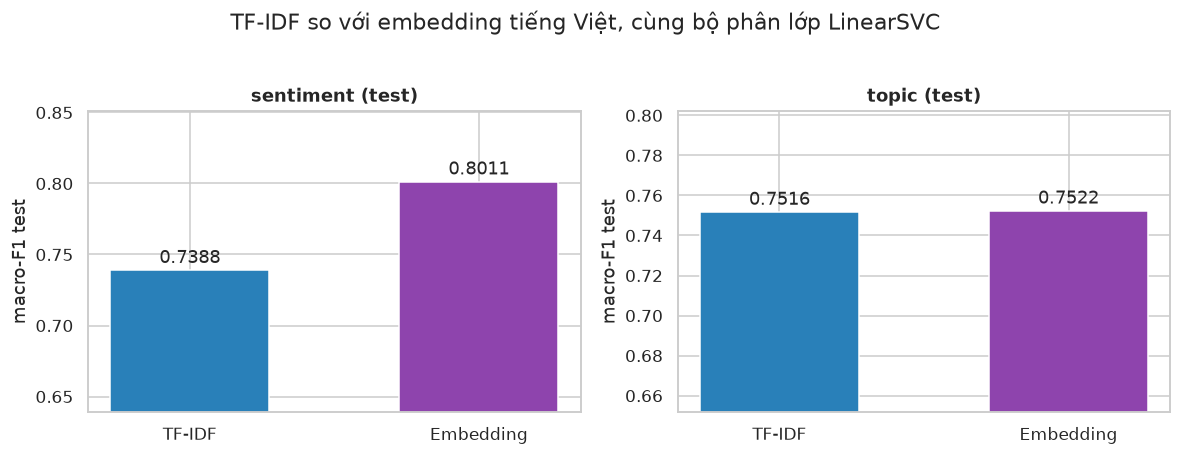

**Hình 7.** Macro-F1 trên test, với `sentiment`, embedding đạt 0.8011 so với TF-IDF 0.7388 (+6.2 điểm, tốt hơn rõ rệt); với `topic`, embedding đạt 0.7522 so với TF-IDF 0.7516 (+0.1 điểm, ngang bằng). Kết luận: biểu diễn câu bằng embedding tiếng Việt giúp ích rõ với nhãn cảm xúc, còn với nhãn chủ đề thì TF-IDF đã đủ.

In [36]:
e2 = []
for task in TASKS:
    for role, lab in [(BEST_FAMILY[task], "TF-IDF"), ("embedding", "Embedding")]:
        r = test_res[(test_res["task"] == task) & (test_res["role"] == role)].iloc[0]
        e2.append({"task": task, "features": lab, "macro_f1": r["test_macro_f1"], "acc": r["test_acc"]})
e2 = pd.DataFrame(e2)
E2 = {t: e2[e2["task"] == t].set_index("features") for t in TASKS}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, task in zip(axes, TASKS):
    d = e2[e2["task"] == task]
    bars = ax.bar(d["features"], d["macro_f1"], color=["#2980b9", "#8e44ad"], width=0.55)
    ax.bar_label(bars, labels=[f"{v:.4f}" for v in d["macro_f1"]], padding=2)
    ax.set_ylim(max(0, d["macro_f1"].min() - 0.1), min(1, d["macro_f1"].max() + 0.05))
    ax.set_title(f"{task} (test)"); ax.set_ylabel("macro-F1 test")
fig.suptitle(f"TF-IDF so với embedding tiếng Việt, cùng bộ phân lớp {BEST_FAMILY['sentiment']}", y=1.03)
fig.tight_layout()

def verdict(task):
    d = 100 * (E2[task].loc["Embedding", "macro_f1"] - E2[task].loc["TF-IDF", "macro_f1"])
    return d, ("tốt hơn rõ rệt" if d >= 1 else "ngang bằng" if d > -1 else "kém hơn")
parts = []
for task in TASKS:
    d, v = verdict(task)
    parts.append(f"với `{task}`, embedding đạt {E2[task].loc['Embedding','macro_f1']:.4f} so với TF-IDF "
                 f"{E2[task].loc['TF-IDF','macro_f1']:.4f} ({d:+.1f} điểm, {v})")
show_fig(fig, "fig07_tfidf_vs_embedding",
    "Macro-F1 trên test, " + "; ".join(parts) + ". Kết luận: biểu diễn câu bằng embedding tiếng Việt giúp ích rõ "
    "với nhãn cảm xúc, còn với nhãn chủ đề thì TF-IDF đã đủ.")

### 7.4 Mô hình dựa vào những từ nào?
Mô hình cuối cùng dùng embedding 1024 chiều, các chiều này không ứng với từ nào nên không đọc được mô hình dựa vào
từ gì. Vì vậy mục này phân tích **mô hình TF-IDF tốt nhất**, LinearSVC trên TF-IDF (mục 6.2). LinearSVC có một trọng
số cho mỗi cặp (lớp, n-gram): trọng số dương lớn nghĩa là n-gram đó đẩy câu về lớp này. Nhóm lấy 12 n-gram mạnh nhất
của mỗi lớp cảm xúc, rồi **kiểm chứng** chúng có thật sự quyết định không: xóa 20 n-gram mạnh nhất của mỗi lớp khỏi
vector test và so sánh mức giảm macro-F1 với việc xóa cùng số lượng n-gram *ngẫu nhiên*.

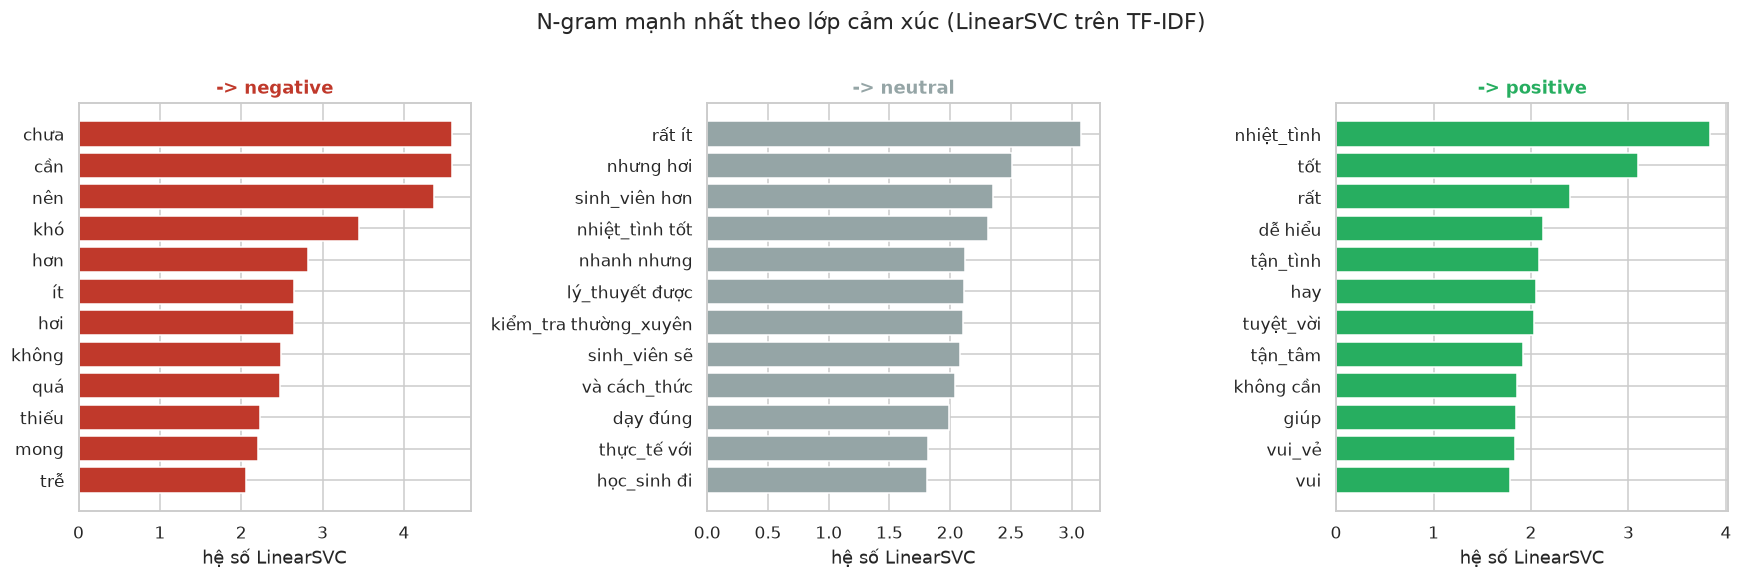

**Hình 8.** Tích cực dựa vào 'nhiệt_tình' (+3.83), 'tốt' (+3.10), 'rất' (+2.40); tiêu cực dựa vào 'chưa' (+4.59), 'cần' (+4.59), 'nên' (+4.37); trung tính dựa vào 'rất ít' (+3.08), 'nhưng hơi' (+2.51), 'sinh_viên hơn' (+2.35). **Kiểm chứng:** xóa 60 n-gram mạnh nhất này khỏi câu test làm macro-F1 giảm từ 0.7388 xuống 0.6544, trong khi xóa 60 n-gram ngẫu nhiên chỉ còn 0.7373 (trung bình 5 lần). Kết luận: một nhóm nhỏ từ khen / chê dễ hiểu quyết định phần lớn dự đoán, nên mô hình dễ giải thích cho người dùng, nhưng cũng dễ bị đánh lừa bởi câu trộn lẫn khen và chê.

In [37]:
i_tfidf = cfg_index("sentiment", BEST_FAMILY["sentiment"])
vec, clf = TEST_MODEL[i_tfidf].steps[0][1], TEST_MODEL[i_tfidf].steps[1][1]
feat = vec.get_feature_names_out()
coef = pd.DataFrame(clf.coef_, index=le_sent.classes_, columns=feat)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
TOPW = {}
for ax, lab in zip(axes, SENT_ORDER):
    top = coef.loc[lab].nlargest(12)
    TOPW[lab] = top
    ax.barh(top.index[::-1], top.values[::-1], color=SENT_COLORS[lab])
    ax.set_title(f"-> {lab}", color=SENT_COLORS[lab]); ax.set_xlabel(f"hệ số {BEST_FAMILY['sentiment']}")
fig.suptitle(f"N-gram mạnh nhất theo lớp cảm xúc ({BEST_FAMILY['sentiment']} trên TF-IDF)", y=1.01)
fig.tight_layout()

X_te = vec.transform(test_df["text_seg"])
top_idx = sorted({vec.vocabulary_[w] for lab in SENT_ORDER for w in coef.loc[lab].nlargest(20).index})
def f1_without(cols):
    keep = np.ones(X_te.shape[1]); keep[cols] = 0
    return f1_score(test_df["y_sent"], clf.predict(X_te @ sp.diags(keep)), average="macro")
rng = np.random.default_rng(SEED)
E4 = {"base": f1_score(test_df["y_sent"], clf.predict(X_te), average="macro"), "top": f1_without(top_idx),
      "rand": np.mean([f1_without(rng.choice(len(feat), len(top_idx), replace=False)) for _ in range(5)]),
      "k": len(top_idx)}

w = lambda lab, k: ", ".join(f"'{t}' ({v:+.2f})" for t, v in TOPW[lab].head(k).items())
show_fig(fig, "fig08_top_ngrams",
    f"Tích cực dựa vào {w('positive', 3)}; tiêu cực dựa vào {w('negative', 3)}; trung tính dựa vào {w('neutral', 3)}. "
    f"**Kiểm chứng:** xóa {E4['k']} n-gram mạnh nhất này khỏi câu test làm macro-F1 giảm từ {E4['base']:.4f} xuống "
    f"{E4['top']:.4f}, trong khi xóa {E4['k']} n-gram ngẫu nhiên chỉ còn {E4['rand']:.4f} (trung bình 5 lần). Kết luận: "
    f"một nhóm nhỏ từ khen / chê dễ hiểu quyết định phần lớn dự đoán, nên mô hình dễ giải thích cho người dùng, "
    f"nhưng cũng dễ bị đánh lừa bởi câu trộn lẫn khen và chê.")

**Nhận xét.** Tín hiệu `negative` mạnh nhất là *chưa* và các động từ góp ý *cần*, *nên*: theo hướng dẫn gán nhãn (mục 2.2), một đề nghị cải thiện (*"thầy nên cho thêm bài tập"*) được tính là `negative`, nên lớp này chứa cả lời góp ý chứ không chỉ lời phàn nàn. Tín hiệu `positive` là các từ khen *nhiệt_tình*, *tốt*. Các n-gram mạnh nhất của `neutral` (*rất ít*, *nhưng hơi*) lại mang sắc thái chê nhẹ hoặc lưng chừng, cho thấy lớp này không có từ vựng riêng rõ ràng, cũng là lý do `neutral` được nhận ra kém nhất (mục 7.2). Xóa 60 n-gram mạnh nhất làm macro-F1 giảm từ 0.7388 xuống 0.6544, còn xóa 60 n-gram ngẫu nhiên gần như không đổi (0.7373).

Các n-gram vừa đẩy câu về `negative` mạnh, vừa chủ yếu xuất hiện ở câu về **cơ sở vật chất** (ít nhất 50% số lần xuất hiện ở train thuộc chủ đề `facility`) cho thấy sinh viên phàn nàn gì về cơ sở vật chất:

In [38]:
tr_counts = vec.transform(train_df["text_seg"]) > 0
fac_mask = (train_df["topic"] == "facility").values
occ_all = np.asarray(tr_counts.sum(axis=0)).ravel()
occ_fac = np.asarray(tr_counts[np.where(fac_mask)[0]].sum(axis=0)).ravel()
fac_share = pd.Series(np.divide(occ_fac, occ_all, out=np.zeros(len(feat)), where=occ_all > 0), index=feat)
fac_neg = (coef.loc["negative"][(fac_share >= 0.5) & (occ_all >= 3)].nlargest(10).rename("negative_coef")
           .to_frame().assign(**{"facility_share": lambda d: fac_share[d.index].map(pct),
                                 "train_count": lambda d: occ_all[[vec.vocabulary_[t] for t in d.index]]}))
display(fac_neg.round(3))

,negative_coef,facility_share,train_count
máy_chiếu,1.391,89.2%,83
phòng,1.300,86.4%,302
trang thiết_bị,0.953,97.9%,47
wifi,0.945,100.0%,12
máy,0.927,82.6%,109
cao chất_lượng,0.884,81.2%,16
vật_chất,0.875,91.2%,34
không đáp_ứng,0.872,50.0%,22
cơ_sở vật_chất,0.824,90.3%,31
phòng học,0.814,93.6%,94


### 7.5 Mô hình sai ở đâu?
Phân tích lỗi của mô hình `sentiment` cuối cùng trên tập test: trước hết là các kiểu lỗi (nhãn thật bị đoán thành nhãn
nào) kèm ví dụ, sau đó là tỉ lệ lỗi theo độ dài câu, theo việc câu có từ đối lập (*nhưng*, *tuy*, ...), từ góp ý
(*nên*, *cần*, ...) hay từ phủ định (*không*, *chưa*, ...), và theo chủ đề.

In [39]:
err = test_df.assign(pred=le_sent.inverse_transform(TEST_PRED[i_sent]))
err["error"] = err["sentiment"] != err["pred"]
pairs = err[err["error"]].groupby(["sentiment", "pred"]).size().rename("n_errors").reset_index()
pairs = pairs.sort_values("n_errors", ascending=False).reset_index(drop=True)
pairs["share_of_errors"] = (pairs["n_errors"] / pairs["n_errors"].sum()).map(pct)
print(f"So cau doan sai: {err['error'].sum()} / {len(err)} ({err['error'].mean():.1%})")
display(pairs)

examples = pd.concat([g.sample(min(2, len(g)), random_state=SEED)
                      for _, g in err[err["error"]].groupby(["sentiment", "pred"])])
with pd.option_context("display.max_colwidth", 120):
    display(examples[["sentence", "sentiment", "pred"]].reset_index(drop=True))

So cau doan sai: 263 / 3166 (8.3%)


,sentiment,pred,n_errors,share_of_errors
0,positive,negative,67,25.5%
1,neutral,positive,48,18.3%
2,positive,neutral,47,17.9%
3,negative,neutral,36,13.7%
4,negative,positive,35,13.3%
5,neutral,negative,30,11.4%


,sentence,sentiment,pred
0,nhiều khi tụi em nghĩ là thầy có biết gì không đây .,negative,neutral
1,nhiều seminar .,negative,neutral
2,"bổ sung nhiều bài tập , hướng dẫn thảo luận tại lớp .",negative,positive
3,giáo viên giảng dạy khá nhanh .,negative,positive
4,chô tiếng việt giống như là copy nguyên văn từ google dịch vậy .,neutral,negative
5,"bài tập thầy cho cũng đòi hỏi phải đến lớp , nghe giảng và phải hiểu thật sự mới làm được .",neutral,negative
6,giáo viên tạo nhiều cơ hội cho sinh viên được luyện nói tiếng anh trên lớp .,neutral,positive
7,mỗi dạng bài thì thầy ghi ra 3 câu bài tập là ổn rồi .,neutral,positive
8,cho các nhóm lên trình bày để tránh việc các bạn copy bài trên mạng và không hiểu bài .,positive,negative
9,cần có nhiều giảng viên có phương pháp dạy như thầy wzjwz147 .,positive,negative


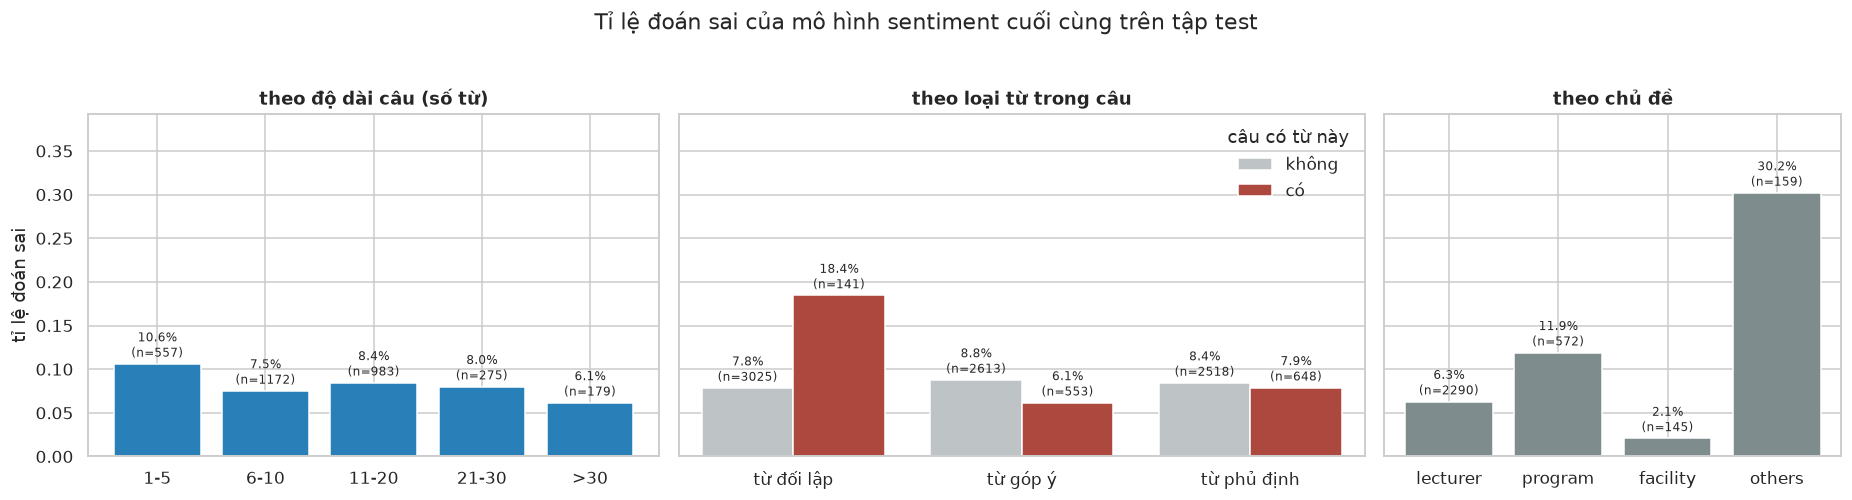

**Hình 9.** Tỉ lệ đoán sai theo độ dài câu: 1-5 từ 10.6%, 6-10 từ 7.5%, 11-20 từ 8.4%, 21-30 từ 8.0%, >30 từ 6.1%, tức là câu ngắn dễ sai hơn câu dài. Theo loại từ: câu có từ đối lập sai 18.4% so với 7.8% khi không có; câu có từ góp ý sai 6.1% so với 8.8% khi không có; câu có từ phủ định sai 7.9% so với 8.4% khi không có. Theo chủ đề, *others* sai nhiều nhất (30.2%, so với 8.3% trên toàn tập test). Kết luận: yếu tố làm tỉ lệ sai tăng mạnh nhất là từ đối lập (gấp 2.4 lần) và chủ đề *others*.

In [40]:
CONTRAST = ["nhưng", "tuy", "mặc dù", "tuy nhiên", "có điều", "song"]
SUGGEST = ["nên", "cần", "mong", "hy vọng", "hi vọng", "đề nghị", "muốn", "hãy"]
NEGATION = ["không", "chưa", "chẳng"]

def has_any(s, words):
    return any(re.search(rf"(^| ){w}( |$)", s) for w in words)

err["length"] = pd.cut(err["n_words"], bins=[0, 5, 10, 20, 30, np.inf], labels=["1-5", "6-10", "11-20", "21-30", ">30"])
for name, words in [("contrast", CONTRAST), ("suggestion", SUGGEST), ("negation", NEGATION)]:
    err[name] = err["text_clean"].map(lambda s: has_any(s, words))

by_length = err.groupby("length", observed=True)["error"].agg(["mean", "size"])
by_word = pd.DataFrame([(name, has, err.loc[err[name] == has, "error"].mean(), (err[name] == has).sum())
                        for name in ["contrast", "suggestion", "negation"] for has in [True, False]],
                       columns=["word_type", "has_word", "mean", "size"])
by_topic = err.groupby("topic")["error"].agg(["mean", "size"]).loc[TOPIC_ORDER]

def bar_labels(ax, bars, rates, sizes):
    ax.bar_label(bars, labels=[f"{100*r:.1f}%\n(n={n})" for r, n in zip(rates, sizes)], fontsize=8, padding=2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True, gridspec_kw={"width_ratios": [5, 6, 4]})
bars = axes[0].bar(by_length.index.astype(str), by_length["mean"], color="#2980b9")
bar_labels(axes[0], bars, by_length["mean"], by_length["size"])
axes[0].set_title("theo độ dài câu (số từ)"); axes[0].set_ylabel("tỉ lệ đoán sai")
WORD_VI = {"contrast": "từ đối lập", "suggestion": "từ góp ý", "negation": "từ phủ định"}
plot_word = by_word.assign(word=by_word["word_type"].map(WORD_VI), has=by_word["has_word"].map({True: "có", False: "không"}))
sns.barplot(data=plot_word, x="word", y="mean", hue="has", hue_order=["không", "có"], ax=axes[1],
            palette={"có": "#c0392b", "không": "#bdc3c7"})
for cont, has in zip(axes[1].containers, ["không", "có"]):
    grp = plot_word[plot_word["has"] == has]
    bar_labels(axes[1], cont, grp["mean"], grp["size"])
axes[1].set_title("theo loại từ trong câu"); axes[1].set_xlabel(""); axes[1].legend(title="câu có từ này", frameon=False)
bars = axes[2].bar(by_topic.index, by_topic["mean"], color="#7f8c8d")
bar_labels(axes[2], bars, by_topic["mean"], by_topic["size"])
axes[2].set_title("theo chủ đề")
axes[0].set_ylim(0, max(by_length["mean"].max(), by_word["mean"].max(), by_topic["mean"].max()) * 1.3)
fig.suptitle("Tỉ lệ đoán sai của mô hình sentiment cuối cùng trên tập test", y=1.03)
fig.tight_layout()

rate = lambda name, has: by_word[(by_word["word_type"] == name) & (by_word["has_word"] == has)]["mean"].iloc[0]
ratio = {name: rate(name, True) / rate(name, False) for name in WORD_VI}
strongest = max(ratio, key=ratio.get)
worst_topic = by_topic["mean"].idxmax()
length_txt = ", ".join(f"{k} từ {pct(v)}" for k, v in by_length["mean"].items())
trend = ("câu ngắn dễ sai hơn câu dài" if by_length["mean"].iloc[0] > by_length["mean"].iloc[-1]
         else "câu dài dễ sai hơn câu ngắn")
words_txt = "; ".join(f"câu có {WORD_VI[n]} sai {pct(rate(n, True))} so với {pct(rate(n, False))} khi không có" for n in WORD_VI)
show_fig(fig, "fig09_error_analysis",
    f"Tỉ lệ đoán sai theo độ dài câu: {length_txt}, tức là {trend}. Theo loại từ: {words_txt}. Theo chủ đề, "
    f"*{worst_topic}* sai nhiều nhất ({pct(by_topic.loc[worst_topic, 'mean'])}, so với {pct(err['error'].mean())} trên toàn "
    f"tập test). Kết luận: yếu tố làm tỉ lệ sai tăng mạnh nhất là {WORD_VI[strongest]} (gấp {ratio[strongest]:.1f} lần) "
    f"và chủ đề *{worst_topic}*.")

- **Nhận xét:**
  - Kiểu lỗi: mô hình đoán sai 263 / 3 166 câu (8.3%). Kiểu sai nhiều nhất là câu `positive` bị đoán thành `negative` (67 câu, 25.5% số lỗi). Các lỗi có dính đến `neutral` (bị đoán sai thành `neutral` hoặc từ `neutral` bị đoán sai) chiếm 61.2% số lỗi, dù `neutral` chỉ có 167 câu trong tập test.
  - Từ đối lập: câu có *nhưng*, *tuy*, ... sai 18.4%, gấp 2.4 lần câu không có (7.8%), vì một câu vừa khen vừa chê chỉ được gán một nhãn.
  - Độ dài: câu 1-5 từ sai nhiều nhất (10.6%), câu trên 30 từ sai ít nhất (6.1%).
  - Từ phủ định gần như không ảnh hưởng (7.9% so với 8.4%), còn câu có từ góp ý lại ít sai hơn (6.1% so với 8.8%), vì dữ liệu luôn gán lời góp ý là `negative`.
  - Theo chủ đề, câu thuộc `others` sai nhiều nhất (30.2%), phù hợp với việc `others` là các câu không rõ chủ đề.

### 7.6 Lưu bảng kết quả
Toàn bộ bảng test (mọi cấu hình đã khai báo) được ghi vào `results/text_metrics.csv` và
`results/text_metrics.md`; báo cáo PDF và trang web lấy số liệu từ các file này.

In [41]:
test_res.drop(columns=["fit_predict_s"]).round(4).to_csv(RESULTS_DIR / "text_metrics.csv", index=False)

def md_table(d):
    try:
        return d.to_markdown(index=False)
    except ImportError:
        cols = list(d.columns)
        lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
        return "\n".join(lines + ["| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False)])

head = test_res[["task", "model", "features", "final", "test_acc", "test_macro_f1", "test_weighted_f1"]].round(4)
exp = pd.DataFrame([
    ("tfidf_vs_embedding (sentiment)", f"TF-IDF {E2['sentiment'].loc['TF-IDF','macro_f1']:.4f}",
     f"Embedding {E2['sentiment'].loc['Embedding','macro_f1']:.4f}", "test_macro_f1"),
    ("tfidf_vs_embedding (topic)", f"TF-IDF {E2['topic'].loc['TF-IDF','macro_f1']:.4f}",
     f"Embedding {E2['topic'].loc['Embedding','macro_f1']:.4f}", "test_macro_f1"),
    (f"ngram_ablation ({BEST_FAMILY['sentiment']})", f"erase top-{E4['k']} {E4['top']:.4f}",
     f"erase {E4['k']} random {E4['rand']:.4f} (full {E4['base']:.4f})", "test_macro_f1"),
], columns=["experiment", "A", "B", "metric"])
(RESULTS_DIR / "text_metrics.md").write_text("\n\n".join([
    "# Text (UIT-VSFC): kết quả trên tập test",
    f"Sinh ra bởi `text.ipynb`. Tập test: {len(test_df):,} câu. `final = True` là mô hình chọn theo macro-F1 validation.",
    "## Các mô hình", md_table(head),
    "## Thí nghiệm", md_table(exp),
]), encoding="utf-8")
print(f"Da luu {RESULTS_DIR.relative_to(HERE)}/text_metrics.csv va {RESULTS_DIR.relative_to(HERE)}/text_metrics.md")
display(head)
display(exp)

Da luu results/text_metrics.csv va results/text_metrics.md


,task,model,features,final,test_acc,test_macro_f1,test_weighted_f1
0,sentiment,NaiveBayes,tfidf_seg,False,0.8699,0.5955,0.8466
1,sentiment,LogReg,tfidf_seg,False,0.8692,0.7201,0.8748
2,sentiment,LinearSVC,tfidf_seg,False,0.8961,0.7388,0.8917
3,topic,NaiveBayes,tfidf_seg,False,0.8184,0.5440,0.7809
4,topic,LogReg,tfidf_seg,False,0.8143,0.7283,0.8282
5,topic,LinearSVC,tfidf_seg,False,0.8547,0.7516,0.8562
6,sentiment,LinearSVC,emb,True,0.9169,0.8011,0.9172
7,topic,LinearSVC,emb,True,0.8500,0.7522,0.8574


,experiment,A,B,metric
0,tfidf_vs_embedding (sentiment),TF-IDF 0.7388,Embedding 0.8011,test_macro_f1
1,tfidf_vs_embedding (topic),TF-IDF 0.7516,Embedding 0.7522,test_macro_f1
2,ngram_ablation (LinearSVC),erase top-60 0.6544,erase 60 random 0.7373 (full 0.7388),test_macro_f1


## 8. Dự đoán phản hồi mới

### 8.1 Hàm dự đoán từ văn bản thô
`predict()` chạy toàn bộ quy trình trên văn bản thô: cùng hàm `clean_text()` (NFC, viết tắt, dấu câu), tách từ
bằng `pyvi` (hoặc mã hóa embedding nếu mô hình cuối cùng là mô hình embedding), rồi hai mô hình cuối cùng, và trả
về nhãn cảm xúc và chủ đề.

In [42]:
def _features(texts, features):
    clean = [clean_text(t) for t in texts]
    if features == "emb":
        return encoder.encode(clean, batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    return [ViTokenizer.tokenize(c) for c in clean] if features == "tfidf_seg" else clean

def predict(text):
    out = {"sentence": text}
    for task, le in [("sentiment", le_sent), ("topic", le_topic)]:
        i = cfg_index(task, FINAL[task]["role"])
        out[task] = le.inverse_transform(TEST_MODEL[i].predict(_features([text], TEST_CONFIGS[i]["features"])))[0]
    return out

### 8.2 Thử với các phản hồi mới
Năm câu thử không có trong bộ dữ liệu và được viết như sinh viên gõ thật: có viết tắt (*gv*, *ko*) và dấu
câu dính liền.

In [43]:
demo = ["thầy dạy dễ hiểu nhưng phòng học nóng quá",
        "gv dạy ko hiểu gì cả, nói quá nhanh",
        "wifi trong phòng máy rất yếu, máy chiếu hay bị hỏng",
        "môn học rất bổ ích và thực tế",
        "nên cho thêm bài tập thực hành cuối mỗi chương"]
display(pd.DataFrame([predict(t) for t in demo]))

,sentence,sentiment,topic
0,thầy dạy dễ hiểu nhưng phòng học nóng quá,negative,lecturer
1,"gv dạy ko hiểu gì cả, nói quá nhanh",negative,lecturer
2,"wifi trong phòng máy rất yếu, máy chiếu hay bị...",negative,facility
3,môn học rất bổ ích và thực tế,positive,program
4,nên cho thêm bài tập thực hành cuối mỗi chương,negative,program


**Nhận xét.** Câu có viết tắt (*gv*, *ko*) và dấu câu dính liền vẫn được xử lý nhờ dùng chung `clean_text()`. Câu đề nghị *"nên cho thêm bài tập ..."* được xếp `negative`, đúng hướng dẫn gán nhãn (mục 2.2). Câu đầu tiên vừa khen giảng viên vừa chê phòng học nhưng chỉ nhận một cặp nhãn (`negative`, `lecturer`), nên lời chê về phòng học bị gộp vào chủ đề giảng viên. Mục 8.3 thử tách câu này.

### 8.3 Câu trộn lẫn: tách theo mệnh đề
Vì một câu có thể chứa ý kiến trái chiều, `predict_clauses()` tách câu tại các từ đối lập và phân loại từng mệnh
đề; đây là cách rẻ để vượt qua giới hạn một nhãn cho mỗi câu (mục 7.5), không phải một mô hình đã được đánh giá.

In [44]:
def predict_clauses(text):
    parts = [p.strip(" ,.") for p in re.split(r"\b(?:nhưng|tuy nhiên|mặc dù)\b", text) if p.strip(" ,.")]
    return pd.DataFrame([predict(p) for p in parts])

display(predict_clauses(demo[0]))

,sentence,sentiment,topic
0,thầy dạy dễ hiểu,positive,lecturer
1,phòng học nóng quá,negative,facility


## 9. Kết luận

### 9.1 Tóm tắt kết quả trên tập test

| Nhãn | Mô hình cuối cùng | Accuracy | Macro-F1 | Weighted-F1 | Bài báo gốc (weighted-F1) |
|---|---|---:|---:|---:|---:|
| `sentiment` | embedding tiếng Việt + LinearSVC | 0.9169 | 0.8011 | 0.9172 | khoảng 0.88 |
| `topic` | embedding tiếng Việt + LinearSVC | 0.8500 | 0.7522 | 0.8574 | khoảng 0.84 |

So với baseline Naive Bayes trên TF-IDF, macro-F1 tăng từ 0.5955 lên 0.8011 (`sentiment`) và từ 0.5440 lên 0.7522
(`topic`). So với cùng LinearSVC trên TF-IDF, embedding tiếng Việt tăng 6.2 điểm với `sentiment` nhưng gần như không
đổi với `topic` (+0.1 điểm).

### 9.2 Các câu hỏi đã được trả lời

| # | Câu hỏi | Trả lời (số liệu trên test) |
|---|---|---|
| 1 | Mỗi chủ đề nhận bao nhiêu phản hồi tiêu cực? | `facility` có tỉ lệ tiêu cực cao nhất (95.4%, 474 câu); `lecturer` có tỉ lệ thấp nhất (35.6%) nhưng nhiều câu tiêu cực nhất (2 909 câu, 54.6% tổng số) (mục 4.2). |
| 2 | Bộ phân lớp nào tốt nhất trên TF-IDF? | LinearSVC ở cả hai nhãn, rồi đến Logistic Regression, Naive Bayes thấp nhất (mục 6.2, 7.1). |
| 3 | Embedding tiếng Việt có tốt hơn TF-IDF không? | Có với `sentiment`: macro-F1 0.8011 so với 0.7388 (+6.2 điểm). Với `topic` gần như bằng nhau (0.7522 so với 0.7516). (mục 7.3). |
| 4 | Từ nào làm câu `negative` hay `positive`? | Theo LinearSVC trên TF-IDF: `positive` dựa vào *nhiệt_tình*, *tốt*; `negative` dựa vào *chưa*, *cần*, *nên*. Xóa 60 n-gram mạnh nhất làm macro-F1 giảm từ 0.7388 xuống 0.6544, xóa 60 n-gram ngẫu nhiên chỉ còn 0.7373 (mục 7.4). |
| 5 | Mô hình sai ở đâu? | Sai 8.3% câu test; 61.2% số lỗi dính đến `neutral`; câu có từ đối lập sai 18.4% so với 7.8%; câu chủ đề `others` sai 30.2% (mục 7.5). |

### 9.3 Hạn chế

* **Một nhãn cho mỗi câu.** Câu trộn lẫn (*"thầy dạy dễ hiểu nhưng phòng học nóng quá"*) không được biểu diễn
  đúng và là nguồn lỗi chính. Cách tách theo mệnh đề ở mục 8.3 chỉ là thủ thuật, chưa được đánh giá.
* **Lớp `neutral` và `others` vẫn yếu** (F1 khoảng 0.53 và 0.46): hai lớp nhỏ, không có từ vựng riêng, và một số nhãn mơ hồ.
* **Quy ước gán nhãn:** đề nghị (*nên*, *cần*) được gán `negative`, nên lớp `negative` lẫn cả lời phàn nàn và lời góp ý.
* **Tham số mặc định:** các bộ phân lớp dùng tham số mặc định của scikit-learn, chưa được tinh chỉnh.
* **Embedding chỉ được dùng làm hàm trích đặc trưng**, không fine-tune trên dữ liệu này, và cần GPU để mã hóa câu.
* **Phạm vi dữ liệu:** một trường đại học, văn bản đã được chuẩn hóa (gần như không có viết tắt), nên kết quả trên phản
  hồi kiểu mạng xã hội sẽ thấp hơn.

### 9.4 Hướng mở rộng

Một số hướng chưa được thực hiện trong notebook này:

* Fine-tune trực tiếp mô hình embedding hoặc PhoBERT trên dữ liệu này, thay vì chỉ dùng làm hàm trích đặc trưng.
* Gán nhãn theo mệnh đề để xử lý câu trộn lẫn.
* Thêm nhãn riêng cho *góp ý*, để tách lời đề nghị khỏi lời phàn nàn.
* Thu thập phản hồi từ khoa hoặc trường khác để kiểm tra khả năng tổng quát hóa.